# Exploration de données et Apprentissage (Analyse des relations entre la pollution atmosphérique et les maladies chroniques au Canada)

In [ ]:
!pip install matplotlib statsmodels scipy pandas seaborn scikit-learn numpy imblearn

# Présentation des données 
## 1. Jeu de données des maladies
### 1.1. Présentation générale des données
#### Source des données
Les données proviennent du site officiel Canada.ca, plus précisément du Canadian Chronic Disease Surveillance System (CCDSS), un système national de surveillance piloté par la Public Health Agency of Canada (PHAC).
Le CCDSS est un réseau collaboratif regroupant les systèmes de surveillance des provinces et territoires canadiens. Il couvre l’ensemble des résidents admissibles à l’assurance maladie provinciale ou territoriale.
#### Conditions de recueil des données
Les données sont issues de données administratives de santé, obtenues par le couplage :
des registres d’assurance maladie, des réclamations médicales (consultations), des dossiers d’hospitalisation, et des bases de données de prescriptions médicamenteuses, à l’aide d’un identifiant personnel unique, garantissant un suivi longitudinal fiable.
Chaque maladie est identifiée à partir de définitions de cas standardisées, propres au CCDSS, basées sur le nombre et le type de contacts avec le système de soins (hospitalisations, actes médicaux).
Les données s'étendent de l'année 2000 jusqu'en 2023, avec des restrictions d’âge spécifiques selon la maladie (par exemple : asthme dès 1 an, insuffisance cardiaque à partir de 40 ans, etc.).
#### Qualité des données
Plusieurs traitements sont appliqués pour assurer la confidentialité et la qualité :
* Suppression des données lorsque le nombre de cas est inférieur à 10,
* Arrondi aléatoire des effectifs (au multiple de 5),
* Suppression des estimations dont le coefficient de variation dépasse 33,3 %,
* Standardisation par âge selon la population canadienne de 2021,
* Agrégation des groupes d’âge selon des classes de cycle de vie.

Une attention particulière est requise pour la période COVID-19, durant laquelle les comportements de recours aux soins ont pu influencer les indicateurs.

### 1.2. Description du jeu de données
#### Nombre de fichiers
Initialement, un fichier par maladie :
* Asthme,
* Insuffisance cardiaque,
* Hypertension,
* Infarctus aigu du myocarde,
* COPD.

On a choisi cinq maladies chroniques tel que deux sont respiratoires (Asthme et COPD) et trois sont cardiovasculaires (Insuffisance cardiaque, Hypertension, Infarctus aigu du myocarde).

Dans la partie suivante du rendu ces fichiers seront nettoyés puis fusionnés en un seul dataframe final.
#### Individus statistiques
Un individu statistique correspond à :
* une année, une région canadienne, un sexe, avec des indicateurs de santé agrégés (par exemple : le nombre de cas et le taux par 100,000).

Dans ce jeu de données, on a 192 individus distincts.
#### Variables du dataframe maladies
Principales variables :
* Année : année de surveillance (de 2000 à 2023),
* Région : province ou région agrégée (on a pris en compte les régions : "Ontario", "British Columbia", "Quebec", "Prince Edward Island", "Nova Scotia"),
* Sexe : hommes ou femmes,
* Nb de cas (maladie) : nombre de cas observés,
* Taux (par 100 000) (maladie) : taux standardisé par âge.

Ces variables décrivent l’évolution temporelle et spatiale des maladies chroniques au Canada.

#### Activité derrière les données
Ces données reflètent :
* la prévalence et l’incidence des maladies chroniques,
* les tendances de santé publique à long terme,
* et indirectement les effets de facteurs démographiques, environnementaux et socio-économiques.

## 2. Jeu de données de la qualité de l'air
### 2.1. Présentation générale des données
#### Source des données
Les données sur la qualité de l’air proviennent du site officiel Canada.ca, et sont produites par Environnement et Changement climatique Canada (ECCC) dans le cadre des indicateurs canadiens de la qualité de l’air.

Les indicateurs sont calculés à partir des données de la base de données pancanadienne sur la qualité de l’air, maintenue par ECCC, alimentée par :
* le Réseau national de surveillance de la pollution atmosphérique (RNSPA), actif depuis 1969,
* le Réseau canadien d’échantillonnage des précipitations et de l’air, destiné à la surveillance hors zones urbaines.

Les données proviennent de stations de mesure fixes, réparties sur l’ensemble du territoire canadien.

Ces indicateurs s’inscrivent dans les politiques publiques canadiennes de surveillance environnementale et de santé publique, et sont également utilisés pour le suivi des Objectifs de développement durable (ODD) et de la Stratégie fédérale de développement durable.

#### Méthodes de calcul
Les concentrations sont mesurées aux stations puis agrégées pour produire des indicateurs :
* nationaux,
* régionaux,
* et urbains.

Des analyses statistiques de tendance sont réalisées sur des périodes de 15 ans.

Les résultats sont comparés, à titre indicatif, aux Normes canadiennes de qualité de l’air ambiant (NCQAA – 2020).
#### Qualité des données
* Certaines données sont exclues lorsqu’elles ne respectent pas les critères d’exhaustivité reconnus internationalement (OMS, EPA, CCME).
* En 2020, aucune station ne satisfaisait les critères pour les COV, ce qui limite l’analyse de ce polluant à la période 2006–2019.
* Des révisions et corrections peuvent être appliquées rétroactivement aux séries temporelles.

### 2.2. Description du jeu de données
#### Nombre de fichiers
Initialement, un fichier par polluant : 
* PM2.5,
* O3,
* NO2,
* SO2,
* COV.

Dans la partie suivante du rendu ces fichiers seront nettoyés puis fusionnés en un seul dataframe final.
#### Individus statistiques
Un individu statistique correspond à :
* une observation annuelle pour une région donnée, caractérisée par les concentrations moyennes des cinq polluants atmosphériques pris en compte.

Dans ce jeu de données, on a 60 individus distincts.
#### Variables du dataframe de la qualité de l'air
Principales variables :
* Année : année de mesure (de 2006 à 2020).
* Région : province ou région agrégée (on a pris en compte les régions : "Canada atlantique", "Sud du Québec", "Sud de l'Ontario", "Prairies et nord de l'Ontario", "Colombie-Britannique")
* Concentration moyenne PM2.5 (µg/m³) : dit particules fines, ce sont des particules qui pénètrent profondément dans les poumons, associées à des effets respiratoires et cardiovasculaires, crises d’asthme, crises cardiaques et cancer du poumon.
* Concentration moyenne O₃ (ppb) : dit Ozone troposphérique, c'est un composant majeur du smog, responsable d’irritations respiratoires, de l’aggravation de l’asthme et d’une réduction de la fonction pulmonaire.
* Concentration moyenne NO₂ (ppb) : dit Dioxyde d’azote, irrite les voies respiratoires, contribue à l’asthme et aux allergies, et joue un rôle dans la formation de l’O₃ et des PM2.5.
* Concentration moyenne SO₂ (ppb) : dit Dioxyde de soufre, impacte la fonction pulmonaire, contribue aux dépôts acides et à la dégradation des écosystèmes.
* Concentration moyenne COV (ppbC) : dit Composés organiques volatils, polluants aux effets variés (irritations, troubles neurologiques, atteintes hépatiques et rénales), certains étant classés toxiques et cancérigènes.
#### Activité derrière les données
La qualité de l’air est un enjeu majeur de santé publique et d’environnement. Les polluants atmosphériques étudiés proviennent principalement :
des activités humaines (transport, production d’électricité, chauffage, industrie),
mais aussi de sources naturelles (feux de forêt, phénomènes atmosphériques).
Ces polluants sont responsables de phénomènes environnementaux tels que le smog, les pluies acides, la dégradation des écosystèmes, ainsi que de nombreux effets sanitaires à court et long termes (maladies respiratoires, cardiovasculaires, cancers, décès prématurés).

## 3. Objectifs et questions du projet 
L’objectif global du projet est de vérifier si il existe des déterminants environnementaux, en lien avec la pollution de l’air, aux maladies chroniques au Canada.

Questions principales abordées :
* Existe-t-il une relation entre les niveaux de pollution atmosphérique (Concentration moyenne des polluants : PM2.5, NO₂, O₃, SO₂, COV dans l'air) et le nombre de cas, ou les taux de certaines maladies chroniques (Asthme, Insuffisance cardiaque, Hypertension, Infarctus aigu du myocarde, COPD) ?
* Peut-on expliquer les variations des taux de maladies par la pollution de l’air, l’année, la région, ou le sexe ?
* Certaines maladies sont-elles plus sensibles à la pollution de l'air que d’autres ?

**Remarque :** Nous traitons les deux jeux de données de telle sorte à conserver (ou calculer) dans chacun d'eux les individus correspondant aux régions suivantes : Québec, Canada Atlantique, Colombie-Britannique et Ontario. L'objectif est d'harmoniser les régions dans les deux jeux de données avant de les fusionner selon les colonnes « Année » et « Région ». Nous avons choisi ces quatre régions spécifiquement car elles présentent des données exhaustives pour toutes les variables, contrairement aux autres régions.

## Nettoyage des données :

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd

In [3]:
# Lecture du fichier csv (et produire dataframe) des concentrations moyennes de dioxyde de soufre (SO2) au canada par region par année
df_so2 = pd.read_csv(
    "concentration_so2.csv",
    header=[0, 1], # 2 lignes d’en-tête
    sep=",",
    decimal=","
)

# Définir les colonnes à garder
colonnes_a_garder_so2 = [
    ('Année', 'Année'),
    ('Canada atlantique', 'Concentration moyenne (ppb)'),
    ('Sud du Québec', 'Concentration moyenne (ppb)'),
    ("Sud de l'Ontario", 'Concentration moyenne (ppb)'),
    ('Prairies et nord de l\'Ontario', 'Concentration moyenne (ppb)'),
    ('Colombie-Britannique', 'Concentration moyenne (ppb)')
]

# Enregistrer dans un nouveau df, les colonnes à garder
df_so2 = df_so2[colonnes_a_garder_so2].copy()

# Aplatir les noms des colonnes du df
df_so2.columns = [
    'Année',
    'Canada atlantique',
    'Québec',
    "Sud de l'Ontario",
    'Prairies et nord Ontario',
    'Colombie-Britannique'
]

# Créer la colonne Ontario (moyenne des deux colonnes : Sud de l'Ontario et Prairies et nord Ontario)
df_so2["Ontario"] = (
    df_so2["Sud de l'Ontario"]
    + df_so2["Prairies et nord Ontario"]
) / 2

# Après les avoir agrégés en une seule colonne, Supprimer les deux colonnes : Sud de l'Ontario et Prairies et nord Ontario
df_so2 = df_so2.drop(
    columns=["Sud de l'Ontario", "Prairies et nord Ontario"]
)

# Afficher le df obtenu
df_so2

,Année,Canada atlantique,Québec,Colombie-Britannique,Ontario
0,2006,1.8,3.3,1.9,2.40
1,2007,2.3,2.5,1.6,2.35
2,2008,1.3,2.6,1.8,2.05
3,2009,1.1,1.9,1.8,1.60
4,2010,0.7,1.7,1.6,1.40
5,2011,0.8,1.4,1.4,1.75
6,2012,1.3,1.8,1.5,1.35
7,2013,1.0,1.7,1.3,1.40
8,2014,0.9,1.5,1.1,1.35
9,2015,0.6,1.3,1.0,1.20


In [4]:
# Lecture du fichier csv (et produire dataframe) des concentrations moyennes de particules fines (P2,5) au canada par region par année
df_p25 = pd.read_csv(
    "concentration_p25.csv",
    header=[0, 1], # 2 lignes d’en-tête
    sep=",",
    decimal=","
)

# Enlever les espaces au debut et à la fin des noms des en-têtes
df_p25.columns = pd.MultiIndex.from_tuples(
    [(lvl0.strip(), lvl1.strip()) for lvl0, lvl1 in df_p25.columns]
)

# Définir les colonnes à garder
colonnes_a_garder_p25 = [
    ('Année', 'Année'),
    ('Canada atlantique', 'Concentration moyenne (microg/m3)'),
    ('Sud du Québec', 'Concentration moyenne (microg/m3)'),
    ("Sud de l'Ontario", 'Concentration moyenne (microg/m3)'),
    ('Prairies et nord de l\'Ontario', 'Concentration moyenne (microg/m3)'),
    ('Colombie-Britannique', 'Concentration moyenne (microg/m3)')
]

# Enregistrer dans un nouveau df, les colonnes à garder
df_p25 = df_p25[colonnes_a_garder_p25].copy()

# Aplatir les noms des colonnes du df
df_p25.columns = [
    'Année',
    'Canada atlantique',
    'Québec',
    "Sud de l'Ontario",
    'Prairies et nord Ontario',
    'Colombie-Britannique'
]

# Créer la colonne Ontario (moyenne des deux colonnes : Sud de l'Ontario et Prairies et nord Ontario)
df_p25["Ontario"] = (
    df_p25["Sud de l'Ontario"]
    + df_p25["Prairies et nord Ontario"]
) / 2

# Après les avoir agrégés en une seule colonne, Supprimer les deux colonnes : Sud de l'Ontario et Prairies et nord Ontario
df_p25 = df_p25.drop(
    columns=["Sud de l'Ontario", "Prairies et nord Ontario"]
)

# Afficher le df obtenu
df_p25

,Année,Canada atlantique,Québec,Colombie-Britannique,Ontario
0,2006,4.7,6.7,5.3,6.00
1,2007,4.4,6.8,4.8,5.90
2,2008,5.1,7.8,4.8,5.65
3,2009,5.8,7.5,5.0,5.25
4,2010,5.2,7.8,5.3,6.95
5,2011,6.2,7.7,4.5,6.45
6,2012,5.4,7.7,4.9,6.20
7,2013,5.9,7.5,6.0,7.05
8,2014,6.4,7.2,6.8,7.35
9,2015,6.1,7.0,7.2,7.35


In [5]:
# Lecture du fichier csv (et produire dataframe) des concentrations moyennes d'ozone troposphérique (O3) au canada par region par année
df_ozone = pd.read_csv(
    "concentration_ozone.csv",
    header=[0, 1], # 2 lignes d’en-tête
    sep=",",
    decimal=","
)

# Enlever les espaces au debut et à la fin des noms des en-têtes
df_ozone.columns = pd.MultiIndex.from_tuples(
    [(lvl0.strip(), lvl1.strip()) for lvl0, lvl1 in df_ozone.columns]
)

# Définir les colonnes à garder
colonnes_a_garder_ozone = [
    ('Année', 'Année'),
    ('Canada atlantique', 'Concentration moyenne (ppb)'),
    ('Sud du Québec', 'Concentration moyenne (ppb)'),
    ("Sud de l'Ontario", 'Concentration moyenne (ppb)'),
    ('Prairies et nord de l\'Ontario', 'Concentration moyenne (ppb)'),
    ('Colombie-Britannique', 'Concentration moyenne (ppb)')
]

# Enregistrer dans un nouveau df, les colonnes à garder
df_ozone = df_ozone[colonnes_a_garder_ozone].copy()

# Aplatir les noms des colonnes du df
df_ozone.columns = [
    'Année',
    'Canada atlantique',
    'Québec',
    "Sud de l'Ontario",
    'Prairies et nord Ontario',
    'Colombie-Britannique'
]

# Créer la colonne Ontario (moyenne des deux colonnes : Sud de l'Ontario et Prairies et nord Ontario)
df_ozone["Ontario"] = (
    df_ozone["Sud de l'Ontario"]
    + df_ozone["Prairies et nord Ontario"]
) / 2

# Après les avoir agrégés en une seule colonne, Supprimer les deux colonnes : Sud de l'Ontario et Prairies et nord Ontario
df_ozone = df_ozone.drop(
    columns=["Sud de l'Ontario", "Prairies et nord Ontario"]
)

# Afficher le df obtenu
df_ozone

,Année,Canada atlantique,Québec,Colombie-Britannique,Ontario
0,2006,33.9,31.0,28.6,34.85
1,2007,32.9,32.3,25.9,35.70
2,2008,33.2,31.2,26.9,34.85
3,2009,31.7,30.4,27.9,34.50
4,2010,33.0,33.2,27.5,35.25
5,2011,32.7,32.3,27.9,36.00
6,2012,32.9,33.6,29.0,35.75
7,2013,33.6,33.9,26.3,35.25
8,2014,33.4,33.1,28.0,34.80
9,2015,33.4,33.8,27.7,35.05


In [6]:
# Lecture du fichier csv (et produire dataframe) des concentrations moyennes de dioxyde d’azote (NO2) au canada par region par année
df_no2 = pd.read_csv(
    "concentration_no2.csv",
    header=[0, 1], # 2 lignes d’en-tête
    sep=",",
    decimal=","
)

# Enlever les espaces au debut et à la fin des noms des en-têtes
df_no2.columns = pd.MultiIndex.from_tuples(
    [(lvl0.strip(), lvl1.strip()) for lvl0, lvl1 in df_no2.columns]
)

# Définir les colonnes à garder
colonnes_a_garder_no2 = [
    ('Année', 'Année'),
    ('Canada atlantique', 'Concentration moyenne (ppb)'),
    ('Sud du Québec', 'Concentration moyenne (ppb)'),
    ("Sud de l'Ontario", 'Concentration moyenne (ppb)'),
    ('Prairies et nord de l\'Ontario', 'Concentration moyenne (ppb)'),
    ('Colombie-Britannique', 'Concentration moyenne (ppb)')
]

# Enregistrer dans un nouveau df, les colonnes à garder
df_no2 = df_no2[colonnes_a_garder_no2].copy()

# Aplatir les noms des colonnes du df
df_no2.columns = [
    'Année',
    'Canada atlantique',
    'Québec',
    "Sud de l'Ontario",
    'Prairies et nord Ontario',
    'Colombie-Britannique'
]

# Créer la colonne Ontario (moyenne des deux colonnes : Sud de l'Ontario et Prairies et nord Ontario)
df_no2["Ontario"] = (
    df_no2["Sud de l'Ontario"]
    + df_no2["Prairies et nord Ontario"]
) / 2

# Après les avoir agrégés en une seule colonne, Supprimer les deux colonnes : Sud de l'Ontario et Prairies et nord Ontario
df_no2 = df_no2.drop(
    columns=["Sud de l'Ontario", "Prairies et nord Ontario"]
)

# Afficher le df obtenu
df_no2

,Année,Canada atlantique,Québec,Colombie-Britannique,Ontario
0,2006,3.3,12.4,12.5,10.80
1,2007,4.0,11.8,11.7,10.10
2,2008,5.2,12.0,11.5,9.55
3,2009,3.4,10.9,11.4,9.25
4,2010,4.1,10.1,9.9,9.00
5,2011,3.8,11.6,9.7,8.50
6,2012,3.2,9.6,10.1,7.80
7,2013,4.0,9.4,9.7,7.90
8,2014,3.6,8.5,9.7,8.05
9,2015,3.3,8.1,9.8,7.55


In [7]:
# Lecture du fichier csv (et produire dataframe) des concentrations moyennes des composés organiques volatils (COV) au canada par region par année
df_cov = pd.read_csv(
    "concentration_cov.csv",
    header=[0, 1], # 2 lignes d’en-tête
    sep=",",
    decimal=","
)

# Enlever les espaces au debut et à la fin des noms des en-têtes
df_cov.columns = pd.MultiIndex.from_tuples(
    [(lvl0.strip(), lvl1.strip()) for lvl0, lvl1 in df_cov.columns]
)

# Définir les colonnes à garder
colonnes_a_garder_cov = [
    ('Année', 'Année'),
    ('Canada atlantique', 'Concentration moyenne (ppbC)'),
    ('Sud du Québec', 'Concentration moyenne (ppbC)'),
    ("Sud de l'Ontario", 'Concentration moyenne (ppbC)'),
    ('Prairies et nord de l\'Ontario', 'Concentration moyenne (ppbC)'),
    ('Colombie-Britannique', 'Concentration moyenne (ppbC)')
]

# Enregistrer dans un nouveau df, les colonnes à garder
df_cov = df_cov[colonnes_a_garder_cov].copy()

# Aplatir les noms des colonnes du df
df_cov.columns = [
    'Année',
    'Canada atlantique',
    'Québec',
    "Sud de l'Ontario",
    'Prairies et nord Ontario',
    'Colombie-Britannique'
]

# Créer la colonne Ontario (moyenne des deux colonnes : Sud de l'Ontario et Prairies et nord Ontario)
df_cov["Ontario"] = (
    df_cov["Sud de l'Ontario"]
    + df_cov["Prairies et nord Ontario"]
) / 2

# Après les avoir agrégés en une seule colonne, Supprimer les deux colonnes : Sud de l'Ontario et Prairies et nord Ontario
df_cov = df_cov.drop(
    columns=["Sud de l'Ontario", "Prairies et nord Ontario"]
)

# Afficher le df obtenu
df_cov

,Année,Canada atlantique,Québec,Colombie-Britannique,Ontario
0,2006,153.7,91.5,154.6,93.65
1,2007,69.4,91.9,190.1,84.05
2,2008,131.1,71.9,147.5,92.25
3,2009,127.6,59.6,195.4,76.95
4,2010,99.9,64.0,172.8,71.95
5,2011,85.8,54.0,128.4,64.50
6,2012,117.7,50.8,97.6,71.40
7,2013,100.1,47.1,117.8,75.70
8,2014,103.0,47.5,118.5,72.25
9,2015,97.8,49.7,113.3,72.90


In [8]:
# Transformation d'un dataframe <df> :
# Passage du format large (1 colonne par région) au format long avec une ligne par (Année, Région)
# Et ajout d'une colonne "Particule" avec la valeur <particule>
def to_long_format(df, particule):
    return df.melt(
        id_vars="Année",
        var_name="Région",
        value_name="Concentration moyenne"
    ).assign(Particule=particule)

In [9]:
# Maintenant on va fusionner nos 5 dataframes en un seul
# On doit tout d'abord les transformer au format long de tel sorte qu'ils ont la même structure
# On appelle la fonction definie precedement afin de transformer tout nos dataframes 
df_so2_long = to_long_format(df_so2,"SO2")
df_p25_long = to_long_format(df_p25,"PM2.5")
df_ozone_long = to_long_format(df_ozone,"Ozone")
df_no2_long = to_long_format(df_no2,"NO2")
df_cov_long = to_long_format(df_cov,"COV")

# Agrégation de tous les dataframes longs en un seul dataframe
# Chaque ligne représente maintenant : (Année, Région, Particule, Concentration moyenne)
df_pollution_long = pd.concat(
    [
        df_so2_long,
        df_p25_long,
        df_ozone_long,
        df_no2_long,
        df_cov_long
    ],
    ignore_index=True
)

# On utilise maintenant "pivot" pour modifier le format du dataframe pour que chaque ligne représente (Année, Région, Concentration moyenne <particule>) : 
df_pollution_air = (
    df_pollution_long
    .pivot(
        index=["Année", "Région"],
        columns="Particule",
        values="Concentration moyenne"
    )
    .reset_index()
)

# enlever le nom de l’index colonne
df_pollution_air.columns.name = None 

df_pollution_air = df_pollution_air.rename(
    columns={
        "SO2": "Concentration moyenne SO2 (ppb)",
        "PM2.5": "Concentration moyenne PM2.5 (microg/m3)",
        "Ozone": "Concentration moyenne O3 (ppb)",
        "NO2": "Concentration moyenne NO2 (ppb)",
        "COV": "Concentration moyenne COV (ppbC)"
    }
)

# Afficher le resultat
df_pollution_air

,Année,Région,Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
0,2006,Canada atlantique,153.70,3.30,33.90,4.70,1.80
1,2006,Colombie-Britannique,154.60,12.50,28.60,5.30,1.90
2,2006,Ontario,93.65,10.80,34.85,6.00,2.40
3,2006,Québec,91.50,12.40,31.00,6.70,3.30
4,2007,Canada atlantique,69.40,4.00,32.90,4.40,2.30
5,2007,Colombie-Britannique,190.10,11.70,25.90,4.80,1.60
6,2007,Ontario,84.05,10.10,35.70,5.90,2.35
7,2007,Québec,91.90,11.80,32.30,6.80,2.50
8,2008,Canada atlantique,131.10,5.20,33.20,5.10,1.30
9,2008,Colombie-Britannique,147.50,11.50,26.90,4.80,1.80


In [10]:
# Passant maintenant aux datasets des maladies au Canada par région par année par sexe
# Soit cette fonction permettant de nettoyer les dataframes provenant des datasets des maladies :
def nettoyer_df_maladie(df):
    """
    Nettoie et standardise un dataframe de maladies par région, année et sexe.
    
    Étapes :
    - Filtrage des géographies d’intérêt
    - Filtrage des sexes
    - Sélection des colonnes utiles
    - Nettoyage des types numériques
    - Standardisation de l’année fiscale
    - Traduction des noms des régions
    - Agrégation des provinces atlantiques
    - Recalcul des taux
    - Renommage et typage final des colonnes
    """

    # Sélectionner les géographies d’intérêt (celles qui sont disponibles dans le dataset de la qualité de l'air)    
    geographies_a_garder = [
        "Ontario",
        "British Columbia",
        "Quebec",
        "Prince Edward Island",
        "Nova Scotia"
    ]

    df = df[df["Geography"].isin(geographies_a_garder)]

    # Filtrer selon le sexe (Males et Females uniquement)
    df = df[df["Sex"].isin(["Males", "Females"])]

    # Sélectionner les colonnes d’intérêt
    colonnes_a_garder = [
        "Geography",
        "Sex",
        "Fiscal year",
        "Rate (per 100,000)",
        "Case counts",
        "Population"
    ]

    df = df[colonnes_a_garder]
    
    # Nettoyage des types numériques (conversion en colonnes numériques)
    colonnes_numeriques = [
        "Rate (per 100,000)",
        "Case counts",
        "Population"
    ]

    for col in colonnes_numeriques:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Standardiser les valeurs de la colonne "Fiscal year" (ex: "2006-2007" → 2006)
    df["Année"] = (
        df["Fiscal year"]
        .str.split("-")
        .str[0]
        .astype(int)
    )

    # Traduire les noms des géographies (pour pouvoir faire la jointure avec l'autre df de la qualité de l'air)
    mapping_geographies = {
        "Quebec": "Québec",
        "British Columbia": "Colombie-Britannique",
        "Ontario": "Ontario",
        "Nova Scotia": "Nova Scotia",
        "Prince Edward Island": "Prince Edward Island"
    }

    df["Geography"] = df["Geography"].map(mapping_geographies)

    # Créer une région agrégée : Canada atlantique qui combine les régions "Nova Scotia" et "Prince Edward Island"
    # Pour une même année + sexe : 
    # Population totale = somme
    # Nombre de cas = somme
    # Taux (rate) = recalcul pondéré

    # Séparer les provinces atlantiques
    atlantic_provinces = ["Nova Scotia", "Prince Edward Island"]

    df_atlantique = df[df["Geography"].isin(atlantic_provinces)]

    # Agrégation statistique des deux colonnes
    # Sommes
    df_atlantique_agg = (
        df_atlantique
        .groupby(["Année", "Sex"], as_index=False)
        .agg({
            "Population": "sum",
            "Case counts": "sum"
        })
    )

    # Ajouter la région agrégée
    df_atlantique_agg["Geography"] = "Canada atlantique"

    # Recalcul du taux (pondéré par population)
    df_atlantique_agg["Rate (per 100,000)"] = (
        df_atlantique_agg["Case counts"]
        / df_atlantique_agg["Population"]
    ) * 100_000

    # Supprimer "Nova Scotia" et "Prince Edward Island" du dataframe initial
    df = df[~df["Geography"].isin(atlantic_provinces)]

    # Ajouter les lignes agrégées au df initial
    df = pd.concat([df, df_atlantique_agg], ignore_index=True)

    
    # Nettoyage final des colonnes (Ordonner, conversion en types adaptés, traduire les noms des colonnes 
    # et enlever la colonne Population car elle concerne la tranche d'age considérée dans chaque dataset qui varie en fonction de la maladie) :
    df = df[
        [
            "Année",
            "Geography",
            "Sex",
            "Rate (per 100,000)",
            "Case counts",
        ]
    ]
    # Conversion en ints et floats
    df["Case counts"] = df["Case counts"].astype("Int64")
    df["Rate (per 100,000)"] = df["Rate (per 100,000)"].astype(float)

    # Traduction des valeurs de la colonne Sex
    df["Sex"] = df["Sex"].replace({"Females": "Femelles"})

    # Traduction des noms des colonnes
    df.rename(
        columns={
            "Geography": "Région",
            "Sex": "Sexe",
            "Rate (per 100,000)": "Taux (par 100,000)",
            "Case counts": "Nb de cas"
        },
        inplace=True
    )

    return df

In [11]:
# Commençant par le dataset de la maladie Asthme
df_asthme = pd.read_csv(
    "Maladie_Asthma.csv",
    skiprows=2
)

df_asthme = nettoyer_df_maladie(df_asthme)

df_asthme

,Année,Région,Sexe,"Taux (par 100,000)",Nb de cas
0,2000,Québec,Femelles,980.000000,34410
1,2000,Québec,Males,839.000000,28550
2,2001,Québec,Femelles,885.000000,30805
3,2001,Québec,Males,773.000000,25905
4,2002,Québec,Femelles,822.000000,28585
...,...,...,...,...,...
187,2021,Canada atlantique,Males,249.892903,1400
188,2022,Canada atlantique,Femelles,305.826116,1785
189,2022,Canada atlantique,Males,288.699120,1665
190,2023,Canada atlantique,Femelles,313.697860,1870


In [12]:
# Passant au dataset de la maladie COPD (Chronic obstructive pulmonary disease)
df_copd = pd.read_csv(
    "Maladie_COPD.csv",
    skiprows=2
)

df_copd = nettoyer_df_maladie(df_copd)

df_copd

,Année,Région,Sexe,"Taux (par 100,000)",Nb de cas
0,2000,Québec,Femelles,1384.000000,24905
1,2000,Québec,Males,1965.000000,25155
2,2001,Québec,Femelles,1226.000000,22365
3,2001,Québec,Males,1715.000000,22160
4,2002,Québec,Femelles,992.000000,18230
...,...,...,...,...,...
187,2021,Canada atlantique,Males,671.111565,2300
188,2022,Canada atlantique,Femelles,611.498837,2300
189,2022,Canada atlantique,Males,695.270462,2455
190,2023,Canada atlantique,Femelles,596.478433,2290


In [13]:
# Passant au dataset de la maladie Heart failure (insuffisance cardiaque) 
df_hf = pd.read_csv(
    "Maladie_Heart_failure.csv",
    skiprows=2
)

df_hf = nettoyer_df_maladie(df_hf)

df_hf

,Année,Région,Sexe,"Taux (par 100,000)",Nb de cas
0,2000,Québec,Femelles,727.000000,11520
1,2000,Québec,Males,1076.000000,11210
2,2001,Québec,Femelles,675.000000,10920
3,2001,Québec,Males,1023.000000,10925
4,2002,Québec,Femelles,625.000000,10300
...,...,...,...,...,...
187,2021,Canada atlantique,Males,577.284525,1935
188,2022,Canada atlantique,Femelles,484.511730,1805
189,2022,Canada atlantique,Males,626.758203,2150
190,2023,Canada atlantique,Femelles,501.349278,1895


In [14]:
# Passant au dataset de la maladie Hypertension 
df_ht = pd.read_csv(
    "Maladie_Hypertension.csv",
    skiprows=2
)

df_ht = nettoyer_df_maladie(df_ht)

df_ht

,Année,Région,Sexe,"Taux (par 100,000)",Nb de cas
0,2000,Québec,Femelles,3814.000000,65005
1,2000,Québec,Males,3375.000000,55615
2,2001,Québec,Femelles,3644.000000,60230
3,2001,Québec,Males,3354.000000,54085
4,2002,Québec,Femelles,3436.000000,56160
...,...,...,...,...,...
187,2021,Canada atlantique,Males,1702.906969,6230
188,2022,Canada atlantique,Femelles,1802.404891,7135
189,2022,Canada atlantique,Males,2145.990803,8120
190,2023,Canada atlantique,Femelles,1850.323375,7510


In [15]:
# Passant au dataset de la maladie Acute myocardial infarction (infarctus aigu du myocarde) 
df_ami = pd.read_csv(
    "Maladie_Acute_myocardial_infarction.csv",
    skiprows=2
)

df_ami = nettoyer_df_maladie(df_ami)

df_ami

,Année,Région,Sexe,"Taux (par 100,000)",Nb de cas
0,2000,Québec,Femelles,231.000000,5935
1,2000,Québec,Males,515.000000,10045
2,2001,Québec,Femelles,225.000000,5930
3,2001,Québec,Males,500.000000,9895
4,2002,Québec,Femelles,224.000000,6025
...,...,...,...,...,...
187,2021,Canada atlantique,Males,351.497440,1720
188,2022,Canada atlantique,Femelles,191.888760,1035
189,2022,Canada atlantique,Males,330.036284,1660
190,2023,Canada atlantique,Femelles,195.138775,1075


In [16]:
# Maintenant on va fusionner les 5 dataframes des differentes maladies

# Ajouter la colonne Maladie à chaque dataframe
df_asthme["Maladie"] = "Asthma"
df_hf["Maladie"] = "Heart Failure"
df_ht["Maladie"] = "Hypertension"
df_ami["Maladie"] = "Acute myocardial infraction"
df_copd["Maladie"] = "COPD"

# Concaténer tous les dataframes
df_maladies = pd.concat(
    [
        df_asthme,
        df_hf,
        df_ht,
        df_ami,
        df_copd
    ],
    ignore_index=True
)

# Ordonner les colonnes
df_maladies = df_maladies[
    [
        "Année",
        "Région",
        "Sexe",
        "Maladie",
        "Taux (par 100,000)",
        "Nb de cas",
    ]
]

# Pivot vers le format large
df_maladies_wide = (
    df_maladies
    .pivot(
        index=["Année", "Région", "Sexe"],
        columns="Maladie",
        values=["Taux (par 100,000)", "Nb de cas"]
    )
    .reset_index()
)

# Aplatir les colonnes 
df_maladies_wide.columns = [
    col[0] if col[1] == "" else f"{col[0]} {col[1]}"
    for col in df_maladies_wide.columns
]

# Ordonner les colonnes 
colonnes_base = ["Année", "Région", "Sexe"]

colonnes_maladies = sorted(
    [c for c in df_maladies_wide.columns if c not in colonnes_base]
)

df_maladies = df_maladies_wide[colonnes_base + colonnes_maladies]

# Afficher le df des maladies
df_maladies

,Année,Région,Sexe,Nb de cas Acute myocardial infraction,Nb de cas Asthma,Nb de cas COPD,Nb de cas Heart Failure,Nb de cas Hypertension,"Taux (par 100,000) Acute myocardial infraction","Taux (par 100,000) Asthma","Taux (par 100,000) COPD","Taux (par 100,000) Heart Failure","Taux (par 100,000) Hypertension"
0,2000,Canada atlantique,Femelles,980,4910,3525,1830,10110,228.289228,934.490503,1180.98365,688.228657,2937.885943
1,2000,Canada atlantique,Males,1470,3800,3485,1700,8920,374.694127,754.979387,1303.510314,712.385023,2666.826118
2,2000,Colombie-Britannique,Femelles,2405,15065,9030,6110,31880,174.0,772.0,909.0,713.0,3384.0
3,2000,Colombie-Britannique,Males,4280,13150,9450,6225,28585,386.0,683.0,1146.0,1005.0,3113.0
4,2000,Ontario,Femelles,9850,62575,30960,20635,99235,245.0,1075.0,1088.0,838.0,3727.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,2023,Colombie-Britannique,Males,4790,9150,8995,11410,39070,221.0,365.0,616.0,844.0,3014.0
188,2023,Ontario,Femelles,7095,35360,23435,26000,78445,98.0,500.0,517.0,554.0,2061.0
189,2023,Ontario,Males,12825,33480,25950,30325,90340,216.0,474.0,641.0,806.0,2527.0
190,2023,Québec,Femelles,9440,14840,16780,13455,30190,219.0,375.0,650.0,478.0,1355.0


In [17]:
# Maintenant on va faire la jointure entre les deux dataframes qu'on a obtenu suite au nettoyage
# Le dataframe de la qualité de l'air (concentration moyenne de chaque particule) au Canada par année, région
# et le dataframe des nombres de cas et taux de chaque maladie au Canada par année, région, sexe 
# la jointure sera faite sur les colonnes Année et Région

# Avant la jointure, on vérifie que les noms des régions sont identiques
# et le type de Année est le même (int) dans les deux dataframes
df_maladies["Année"] = df_maladies["Année"].astype(int)
df_pollution_air["Année"] = df_pollution_air["Année"].astype(int)

# Puis on effectue la jointure
df_maladies_pollution_air = df_maladies.merge(
    df_pollution_air,
    on=["Année", "Région"],
    how="inner"
)

# Affiche le df obtenu
df_maladies_pollution_air

,Année,Région,Sexe,Nb de cas Acute myocardial infraction,Nb de cas Asthma,Nb de cas COPD,Nb de cas Heart Failure,Nb de cas Hypertension,"Taux (par 100,000) Acute myocardial infraction","Taux (par 100,000) Asthma","Taux (par 100,000) COPD","Taux (par 100,000) Heart Failure","Taux (par 100,000) Hypertension",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
0,2006,Canada atlantique,Femelles,960,3630,3460,1535,8085,214.192483,703.93174,1112.379238,517.470966,2453.531599,153.70,3.3,33.90,4.7,1.8
1,2006,Canada atlantique,Males,1530,2890,3140,1480,8445,373.220798,579.87299,1105.361355,549.675023,2609.138938,153.70,3.3,33.90,4.7,1.8
2,2006,Colombie-Britannique,Femelles,2325,12400,8745,6730,33440,143.0,620.0,791.0,677.0,3673.0,154.60,12.5,28.60,5.3,1.9
3,2006,Colombie-Britannique,Males,4040,11030,9235,6915,35090,306.0,561.0,970.0,934.0,3808.0,154.60,12.5,28.60,5.3,1.9
4,2006,Ontario,Femelles,9225,43195,29210,16650,84870,195.0,715.0,907.0,566.0,3223.0,93.65,10.8,34.85,6.0,2.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,2020,Colombie-Britannique,Males,5030,7695,9130,9835,27105,254.0,326.0,687.0,805.0,2312.0,NaN,7.9,27.30,6.8,0.6
116,2020,Ontario,Femelles,7510,23535,16170,18775,53050,114.0,350.0,386.0,441.0,1541.0,NaN,6.1,34.35,5.7,0.9
117,2020,Ontario,Males,13060,19415,18285,20990,61620,239.0,291.0,493.0,619.0,1883.0,NaN,6.1,34.35,5.7,0.9
118,2020,Québec,Femelles,7935,11525,11405,10670,24190,196.0,304.0,464.0,408.0,1201.0,NaN,6.7,33.30,6.3,1.1


In [18]:
df_maladies_pollution_air.to_csv('Canada_gouv_Maladies_Pollution.csv', index=False)

## Analyse Unidimensionnelle :

### Indicateurs de tendance centrale et dispersion

In [ ]:
import sys
!{sys.executable} -m pip install scipy

In [18]:
from scipy.stats import trim_mean

def statistiques_descrip(x):
    """
    Calcule et affiche les statistiques descriptives pour la variable en entrée
    """

    print("--- Statistiques de tendance centrale ---")
    print(f"Moyenne : {x.mean(skipna=True):.3f}")
    print(f"Médiane : {x.median(skipna=True):.3f}")

    print("\n--- Statistiques de dispersion ---")
    # variance corrigée (on divise par (n-1) avec n = nb d'individus)
    print(f"Variance corrigée : {x.var(ddof=1, skipna=True):.3f}")
    print(f"Écart-type : {x.std(ddof=1, skipna=True):.3f}")

    print("\n--- Moyenne tronquée ---")
    # moyenne tronquée (enlève 10% des valeurs les plus petites et les plus grandes)
    print(f"Moyenne tronquée (10%) : {trim_mean(x.dropna(), proportiontocut=0.1):.3f}")

    print("\n--- Quantiles et IQR ---")
    # Quantiles
    print("Quantiles (0.25, 0.5, 0.75) :")
    print(x.quantile([0.25, 0.5, 0.75]))
    
    # IQR
    iqr = x.quantile(0.75) - x.quantile(0.25)
    print(f"Écart interquartile (IQR) : {iqr:.3f}")

    print("\n--- Coefficient de variation ---")
    # Coefficient de variation
    coef_var = x.std(skipna=True) / x.mean(skipna=True)
    print(f"Coefficient de variation : {coef_var:.3f}")

In [19]:
# On va appliquer la fonction qu'on viens de definir sur nos variables numériques
# commençant par la variable : Concentration moyenne COV (ppbC)
x = df_maladies_pollution_air["Concentration moyenne COV (ppbC)"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 91.509
Médiane : 88.100

--- Statistiques de dispersion ---
Variance corrigée : 1375.386
Écart-type : 37.086

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 87.673

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25     64.375
0.50     88.100
0.75    114.400
Name: Concentration moyenne COV (ppbC), dtype: float64
Écart interquartile (IQR) : 50.025

--- Coefficient de variation ---
Coefficient de variation : 0.405


##### Interpretation (Concentration moyenne COV (ppbC)):
Tendance centrale :
La moyenne (≈ 91,5) est supérieure à la médiane (88,1), ce qui suggère une légère asymétrie à droite, avec des valeurs élevées tirant la moyenne vers le haut. La moyenne tronquée (≈ 87,7), plus proche de la médiane, confirme l’influence de valeurs extrêmes.

Dispersion :
L’écart-type élevé (≈ 37,1) et la variance importante traduisent une forte variabilité des concentrations.
L’IQR (≈ 50) indique que 50 % des observations sont comprises entre ~64,4 et ~114,4.

Variabilité relative :
Le coefficient de variation (≈ 40,5 %) révèle une dispersion relative élevée, indiquant une hétérogénéité marquée des données.

In [20]:
# Passant à la variable : Concentration moyenne NO2 (ppb)
x = df_maladies_pollution_air["Concentration moyenne NO2 (ppb)"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 7.835
Médiane : 8.150

--- Statistiques de dispersion ---
Variance corrigée : 8.384
Écart-type : 2.896

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 7.923

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    5.875
0.50    8.150
0.75    9.825
Name: Concentration moyenne NO2 (ppb), dtype: float64
Écart interquartile (IQR) : 3.950

--- Coefficient de variation ---
Coefficient de variation : 0.370


##### Interprétation (Concentration moyenne NO2 (ppb))
Tendance centrale :
La moyenne (≈ 7,84) est légèrement inférieure à la médiane (8,15), suggérant une légère asymétrie à gauche. La moyenne tronquée (≈ 7,92), proche de la moyenne, indique une influence limitée des valeurs extrêmes.

Dispersion :
L’écart-type modéré (≈ 2,90) traduit une variabilité notable mais contenue.
L’IQR (≈ 3,95) montre que 50 % des observations se situent entre ~5,88 et ~9,83.

Variabilité relative :
Le coefficient de variation (≈ 37 %) indique une dispersion relative modérée à élevée

In [21]:
# Passant à la variable : Concentration moyenne O3 (ppb)
x = df_maladies_pollution_air["Concentration moyenne O3 (ppb)"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 32.228
Médiane : 33.250

--- Statistiques de dispersion ---
Variance corrigée : 8.827
Écart-type : 2.971

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 32.494

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    30.050
0.50    33.250
0.75    34.525
Name: Concentration moyenne O3 (ppb), dtype: float64
Écart interquartile (IQR) : 4.475

--- Coefficient de variation ---
Coefficient de variation : 0.092


#### Interprétation (Concentration moyenne O3 (ppb))

Tendance centrale :
La moyenne (≈ 32,23) est légèrement inférieure à la médiane (33,25), suggérant une faible asymétrie à gauche. La moyenne tronquée (≈ 32,49) confirme une distribution globalement symétrique.

Dispersion :
L’écart-type (≈ 2,97) est faible, indiquant une variabilité limitée.
L’IQR (≈ 4,48) montre une concentration des valeurs entre ~30,05 et ~34,53.

Variabilité relative :
Le coefficient de variation (≈ 9,2 %) révèle une très faible dispersion relative, traduisant une grande homogénéité des données.

In [22]:
# Passant à la variable : Concentration moyenne PM2.5 (microg/m3)
x = df_maladies_pollution_air["Concentration moyenne PM2.5 (microg/m3)"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 6.255
Médiane : 6.200

--- Statistiques de dispersion ---
Variance corrigée : 1.103
Écart-type : 1.050

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 6.214

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    5.3750
0.50    6.2000
0.75    6.9625
Name: Concentration moyenne PM2.5 (microg/m3), dtype: float64
Écart interquartile (IQR) : 1.588

--- Coefficient de variation ---
Coefficient de variation : 0.168


#### Interprétation (Concentration moyenne PM2.5 (microg/m³))

Tendance centrale :
La moyenne (≈ 6,26) et la médiane (6,20) sont très proches, indiquant une distribution quasi symétrique. La moyenne tronquée (≈ 6,21) confirme l’absence d’influence marquée de valeurs extrêmes.

Dispersion :
L’écart-type faible (≈ 1,05) traduit une variabilité limitée.
L’IQR (≈ 1,59) montre que la moitié des valeurs est comprise entre ~5,38 et ~6,96.

Variabilité relative :
Le coefficient de variation (≈ 16,8 %) indique une dispersion relative modérée.

In [23]:
# Passant à la variable : Concentration moyenne SO2 (ppb)
x = df_maladies_pollution_air["Concentration moyenne SO2 (ppb)"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 1.350
Médiane : 1.300

--- Statistiques de dispersion ---
Variance corrigée : 0.327
Écart-type : 0.572

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 1.291

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    0.9
0.50    1.3
0.75    1.7
Name: Concentration moyenne SO2 (ppb), dtype: float64
Écart interquartile (IQR) : 0.800

--- Coefficient de variation ---
Coefficient de variation : 0.424


#### Interprétation (Concentration moyenne SO2 (ppb))

Tendance centrale :
La moyenne (≈ 1,35) est légèrement supérieure à la médiane (1,30), suggérant une légère asymétrie à droite. La moyenne tronquée (≈ 1,29) confirme l’influence de quelques valeurs élevées.

Dispersion :
L’écart-type (≈ 0,57) indique une variabilité modérée.
L’IQR (≈ 0,80) montre que 50 % des valeurs se situent entre 0,9 et 1,7.

Variabilité relative :
Le coefficient de variation (≈ 42,4 %) révèle une forte dispersion relative.

In [24]:
# Passant à la variable : Nb de cas Acute myocardial infraction
x = df_maladies_pollution_air["Nb de cas Acute myocardial infraction"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 6267.917
Médiane : 5317.500

--- Statistiques de dispersion ---
Variance corrigée : 19185174.615
Écart-type : 4380.088

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 5925.625

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    2178.75
0.50     5317.5
0.75     9142.5
Name: Nb de cas Acute myocardial infraction, dtype: object
Écart interquartile (IQR) : 6963.750

--- Coefficient de variation ---
Coefficient de variation : 0.699


#### Interprétation (Nombre de cas Acute myocardial infraction)

Tendance centrale :
La moyenne (≈ 6 268) est nettement supérieure à la médiane (≈ 5 318), indiquant une asymétrie à droite, avec des valeurs élevées influençant la moyenne. La moyenne tronquée (≈ 5 926) confirme cet effet.

Dispersion :
L’écart-type élevé (≈ 4 380) traduit une forte variabilité.
L’IQR (≈ 6 964) montre une large dispersion des cas.

Variabilité relative :
Le coefficient de variation (≈ 69,9 %) indique une hétérogénéité très marquée.

In [25]:
# Passant à la variable : Nb de cas Asthma
x = df_maladies_pollution_air["Nb de cas Asthma"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 15069.417
Médiane : 12320.000

--- Statistiques de dispersion ---
Variance corrigée : 130381216.464
Écart-type : 11418.459

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 14077.448

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25    6678.75
0.50    12320.0
0.75    20110.0
Name: Nb de cas Asthma, dtype: object
Écart interquartile (IQR) : 13431.250

--- Coefficient de variation ---
Coefficient de variation : 0.758


#### Interprétation (Nombre de cas Asthma)

Tendance centrale :
La moyenne (≈ 15 069) est supérieure à la médiane (≈ 12 320), suggérant une asymétrie à droite. La moyenne tronquée (≈ 14 077) confirme l’influence de valeurs élevées.

Dispersion :
L’écart-type très élevé (≈ 11 418) traduit une variabilité importante.
L’IQR (≈ 13 431) indique une dispersion très large des observations.

Variabilité relative :
Le coefficient de variation (≈ 75,8 %) révèle une très forte dispersion relative.

In [26]:
# Passant à la variable : Nb de cas COPD
x = df_maladies_pollution_air["Nb de cas COPD"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 15274.167
Médiane : 14900.000

--- Statistiques de dispersion ---
Variance corrigée : 97213655.182
Écart-type : 9859.699

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 14701.094

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25     7490.0
0.50    14900.0
0.75    19562.5
Name: Nb de cas COPD, dtype: object
Écart interquartile (IQR) : 12072.500

--- Coefficient de variation ---
Coefficient de variation : 0.646


#### Interprétation (Nombre de cas COPD)

Tendance centrale :
La moyenne (≈ 15 274) est légèrement supérieure à la médiane (≈ 14 900), indiquant une légère asymétrie à droite. La moyenne tronquée (≈ 14 701) confirme une influence modérée des valeurs extrêmes.

Dispersion :
L’écart-type élevé (≈ 9 860) montre une forte variabilité.
L’IQR (≈ 12 073) traduit une dispersion importante des cas.

Variabilité relative :
Le coefficient de variation (≈ 64,6 %) indique une hétérogénéité marquée.

In [27]:
# Passant à la variable : Nb de cas Heart Failure
x = df_maladies_pollution_air["Nb de cas Heart Failure"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 9650.917
Médiane : 9577.500

--- Statistiques de dispersion ---
Variance corrigée : 38476542.850
Écart-type : 6202.946

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 9357.917

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25     5341.25
0.50      9577.5
0.75    13688.75
Name: Nb de cas Heart Failure, dtype: object
Écart interquartile (IQR) : 8347.500

--- Coefficient de variation ---
Coefficient de variation : 0.643


#### Interprétation (Nombre de cas Heart Failure)

Tendance centrale :
La moyenne (≈ 9 651) et la médiane (≈ 9 578) sont proches, suggérant une distribution relativement symétrique. La moyenne tronquée (≈ 9 358) confirme une influence limitée des valeurs extrêmes.

Dispersion :
L’écart-type élevé (≈ 6 203) traduit une variabilité importante.
L’IQR (≈ 8 348) indique une dispersion notable.

Variabilité relative :
Le coefficient de variation (≈ 64,3 %) révèle une forte dispersion relative.

In [28]:
# Passant à la variable : Nb de cas Hypertension
x = df_maladies_pollution_air["Nb de cas Hypertension"]
statistiques_descrip(x)

--- Statistiques de tendance centrale ---
Moyenne : 34612.250
Médiane : 30172.500

--- Statistiques de dispersion ---
Variance corrigée : 552542731.450
Écart-type : 23506.228

--- Moyenne tronquée ---
Moyenne tronquée (10%) : 32796.719

--- Quantiles et IQR ---
Quantiles (0.25, 0.5, 0.75) :
0.25     17565.0
0.50     30172.5
0.75    48141.25
Name: Nb de cas Hypertension, dtype: object
Écart interquartile (IQR) : 30576.250

--- Coefficient de variation ---
Coefficient de variation : 0.679


#### Interprétation (Nombre de cas Hypertension)

Tendance centrale :
La moyenne (≈ 34 612) est nettement supérieure à la médiane (≈ 30 173), indiquant une asymétrie à droite. La moyenne tronquée (≈ 32 797) confirme l’influence de valeurs élevées.

Dispersion :
L’écart-type très élevé (≈ 23 506) traduit une variabilité extrêmement forte.
L’IQR (≈ 30 576) met en évidence une dispersion très large.

Variabilité relative :
Le coefficient de variation (≈ 67,9 %) indique une hétérogénéité très marquée des données.

### Représentations graphiques

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.distributions.empirical_distribution import ECDF
import scipy.stats as stats

def reps_graphiques_vars(data_column):
    """
    Génère un Boxplot, Histogramme, ECDF et QQ-Plot pour une variable donnée.
    Adapte automatiquement les titres et axes selon le nom de la variable.
    """
    # Nettoyage des données (dropna)
    x = data_column.dropna()
    var_name = data_column.name if data_column.name else "Variable"

    # Configuration de la figure (2 lignes, 2 colonnes)
    plt.figure(figsize=(12, 10))

    # 1. Boxplot
    plt.subplot(2, 2, 1)
    plt.boxplot(x)
    plt.title(f"Boxplot de {var_name}")
    plt.ylabel("Valeurs")

    # 2. Histogramme
    plt.subplot(2, 2, 2)
    plt.hist(x, bins=20, density=True, alpha=0.7, color='skyblue', edgecolor='black')
    plt.title(f"Histogramme de {var_name}")
    plt.xlabel(var_name)
    plt.ylabel("Densité")

    # 3. ECDF (Fonction de répartition)
    plt.subplot(2, 2, 3)
    ecdf = ECDF(x)
    plt.plot(ecdf.x, ecdf.y)
    plt.title(f"ECDF de {var_name}")
    plt.xlabel(var_name)
    plt.ylabel("Probabilité cumulée")
    plt.grid(True, linestyle='--', alpha=0.6)

    # 4. QQ-Plot
    plt.subplot(2, 2, 4)
    stats.probplot(x, plot=plt)
    plt.title(f"QQ-plot de {var_name}")

    plt.tight_layout()
    plt.show()

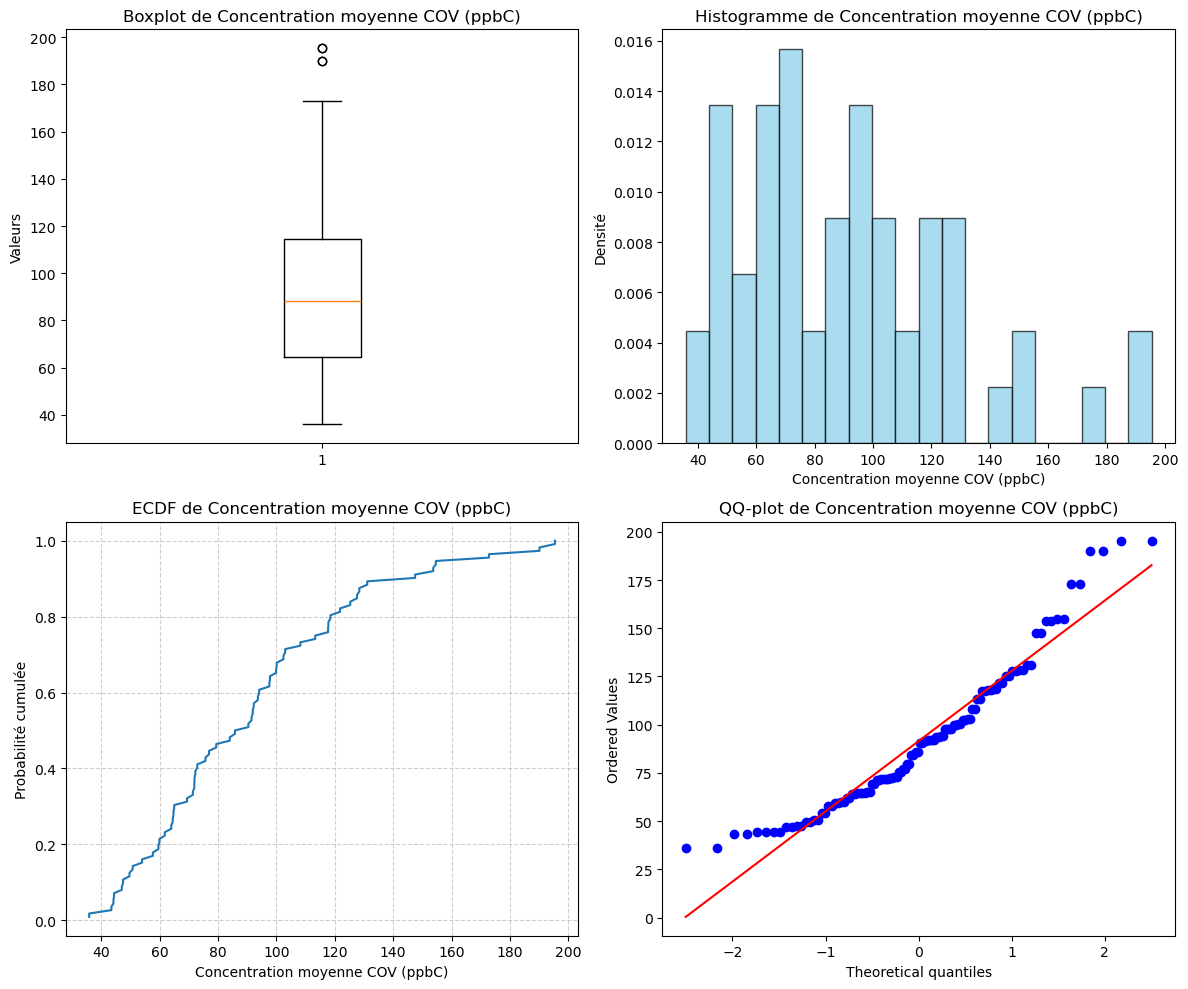

In [ ]:
# commençant par la variable : Concentration moyenne COV (ppbC)
x = df_maladies_pollution_air["Concentration moyenne COV (ppbC)"]
reps_graphiques_vars(x)

#### Interpretation des graphiques (Concentration moyenne COV (ppbC)) : 
Boxplot :
* La concentration moyenne de COV est centrée autour de ~85–90 ppbC.
* La dispersion est assez importante (boîte large).
* Présence de valeurs extrêmes (outliers) (≈ 180–200 ppbC).
* Moustaches de longueurs différentes, indiquant une concentration des valeurs vers le bas (asymétrie positive/à droite) 

Histogramme :
* La majorité des valeurs se situent entre 60 et 120 ppbC.
* La distribution n’est pas parfaitement symétrique.
* La forme suggère une déviation par rapport à une loi normale.

ECDF (La fonction de distribution cumulative empirique) :
* Environ 50 % des observations sont inférieures à ~85 ppbC.
* Près de 90 % des valeurs sont inférieures à ~140 ppbC.

QQ-plot :
* Les points s’écartent de la droite théorique, surtout : dans les queues et pour les valeurs élevées
* Cela indique que la distribution des COV ne suit pas une loi normale.

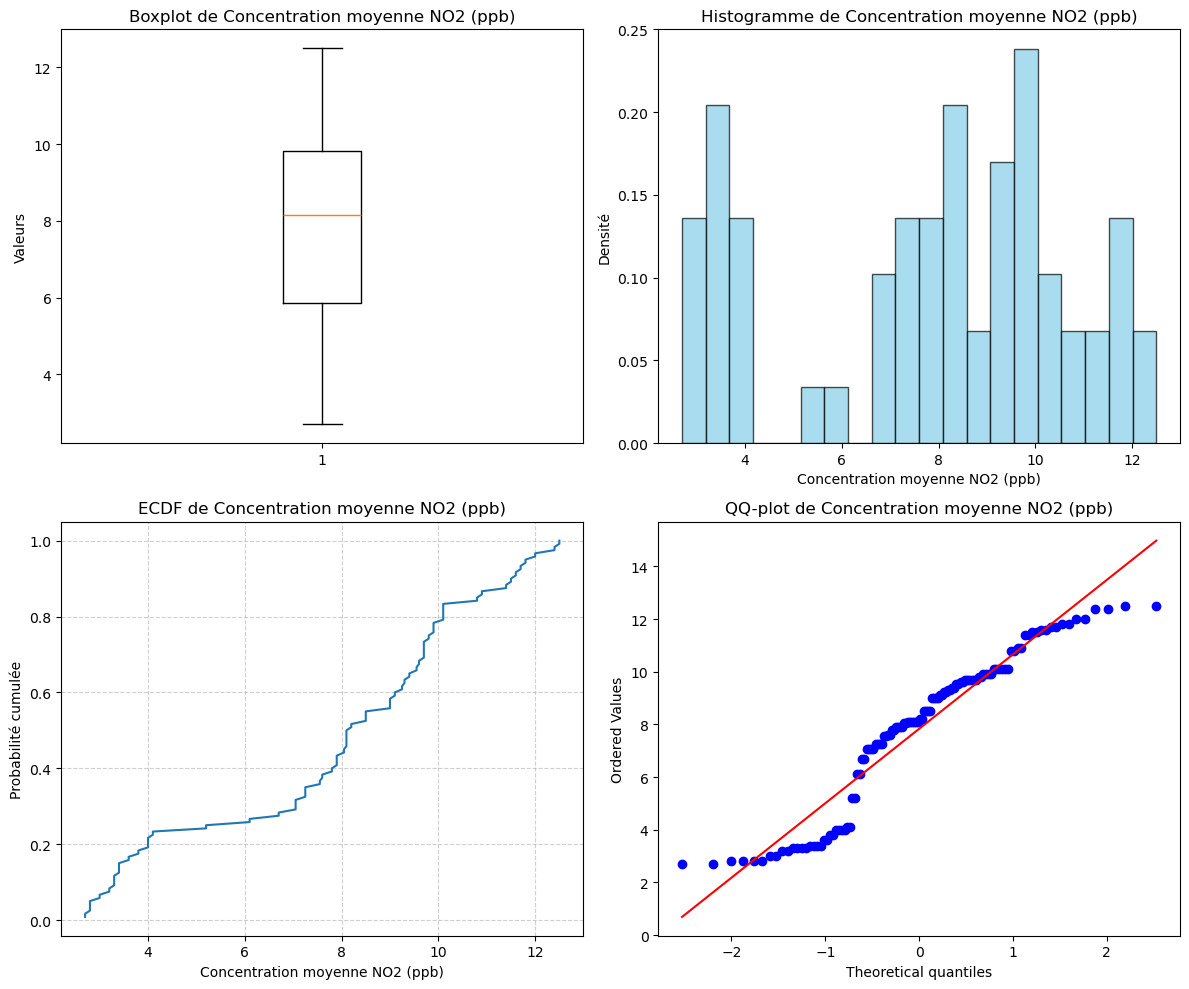

In [ ]:
# Passant à la variable : Concentration moyenne NO2 (ppb)
x = df_maladies_pollution_air["Concentration moyenne NO2 (ppb)"]
reps_graphiques_vars(x)

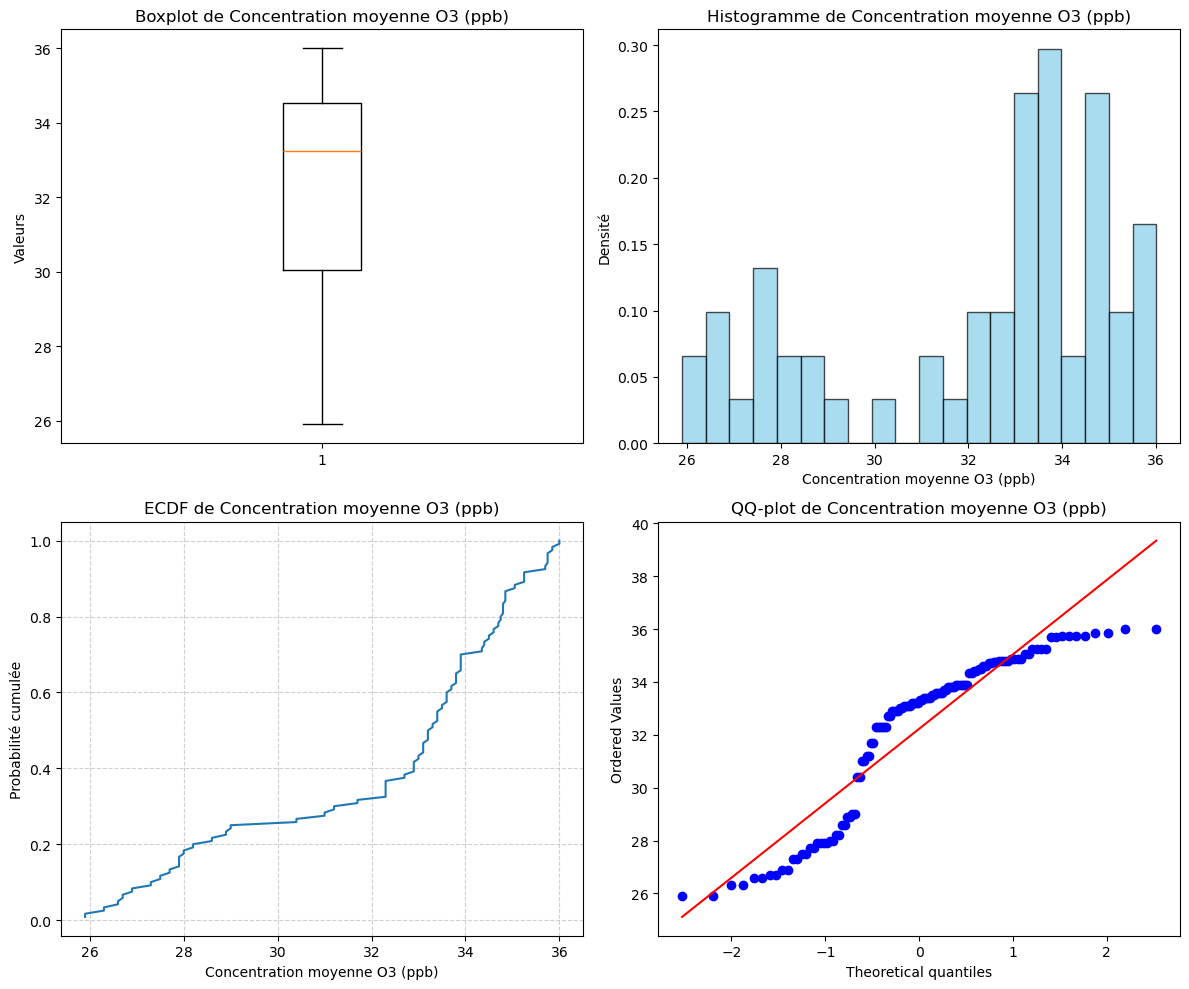

In [ ]:
# Passant à la variable : Concentration moyenne O3 (ppb)
x = df_maladies_pollution_air["Concentration moyenne O3 (ppb)"]
reps_graphiques_vars(x)

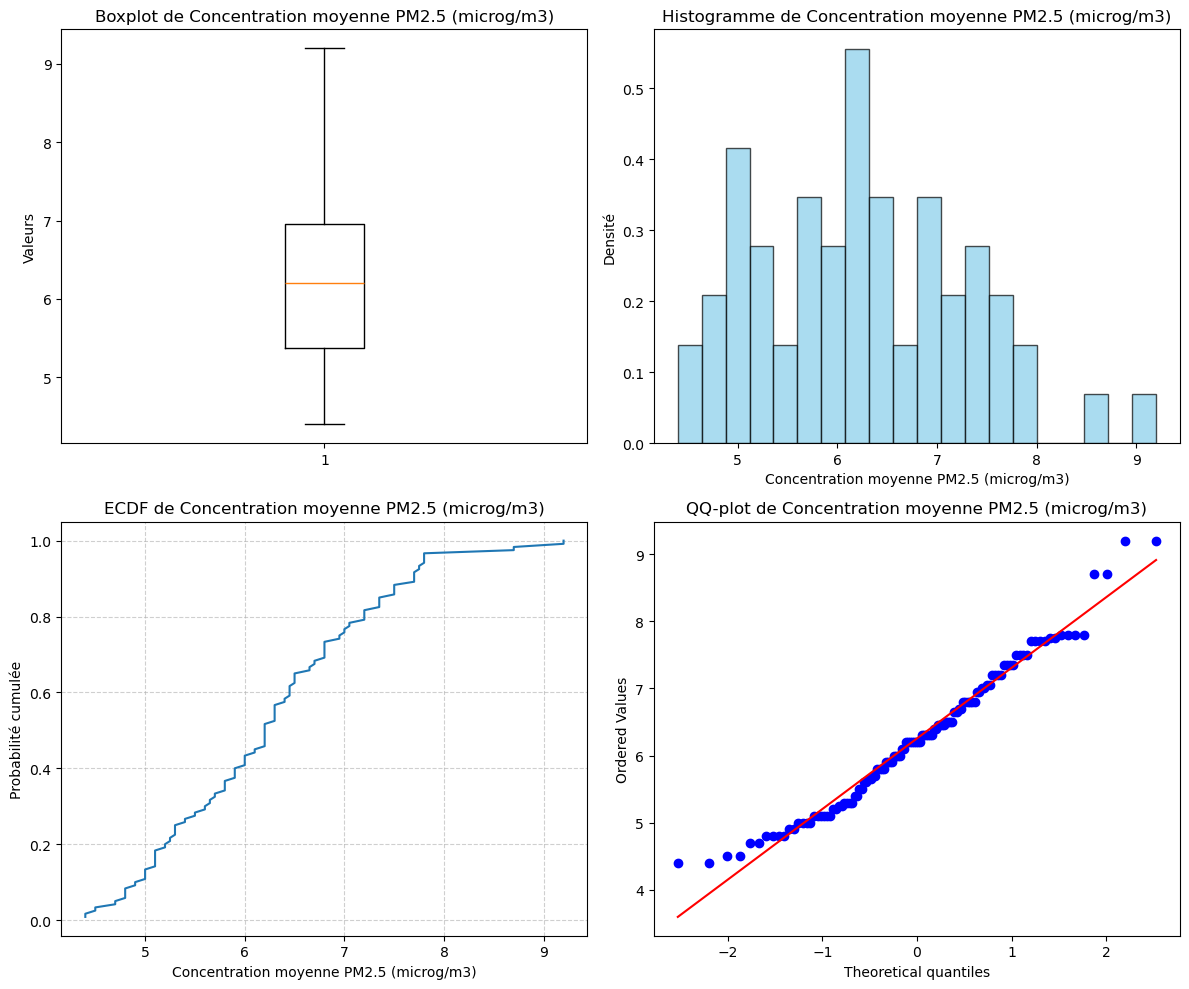

In [ ]:
# Passant à la variable : Concentration moyenne PM2.5 (microg/m3)
x = df_maladies_pollution_air["Concentration moyenne PM2.5 (microg/m3)"]
reps_graphiques_vars(x)

#### Interpretation des graphiques (Concentration moyenne PM2.5 (microg/m3)) : 
Boxplot :
* La concentration moyenne de PM2.5 est centrée autour de ~6.2 microg/m3.
* La dispersion est modérée (boîte relativement compacte).
* Peu ou pas de valeurs aberrantes visibles.
* Légère asymétrie à droite, mais moins marquée que pour les COV.

Histogramme :
* La majorité des valeurs se situent entre 5 et 7.5 microg/m3.
* La distribution est plutôt unimodale.
* La forme est assez symétrique, avec une légère queue à droite.
* Aucune multimodalité nette.

ECDF :
* Environ 50 % des observations sont inférieures à ~6.2 microg/m3.
* Près de 90 % des valeurs sont inférieures à ~8 microg/m3.
* La montée est progressive, indiquant une variabilité maîtrisée.

QQ-plot :
* Les points suivent globalement bien la droite théorique.
* De légers écarts apparaissent dans les queues, surtout pour les valeurs élevées.
* Cela suggère que la distribution est proche d’une loi normale.

In [ ]:
# Afin de vérifier que la distribution de la variable concentration moyenne PM2.5 (microg/m3) suit la loi normale
# on va appliquer le test de normalité (Shapiro-Wilk)
from scipy.stats import shapiro

x = df_maladies_pollution_air["Concentration moyenne PM2.5 (microg/m3)"]
shapiro(x.dropna())

# si p-value > 0.05 -> normalité plausible
# si p-value < 0.05 -> rejet de la normalité

ShapiroResult(statistic=0.973998232437562, pvalue=0.01995245200452624)

p-value obtenue = 0.01 est inférieure à 0.05 donc on rejette l'hypothèse que la distribution de la variable concentration moyenne PM2.5 (microg/m3) suit la loi normale

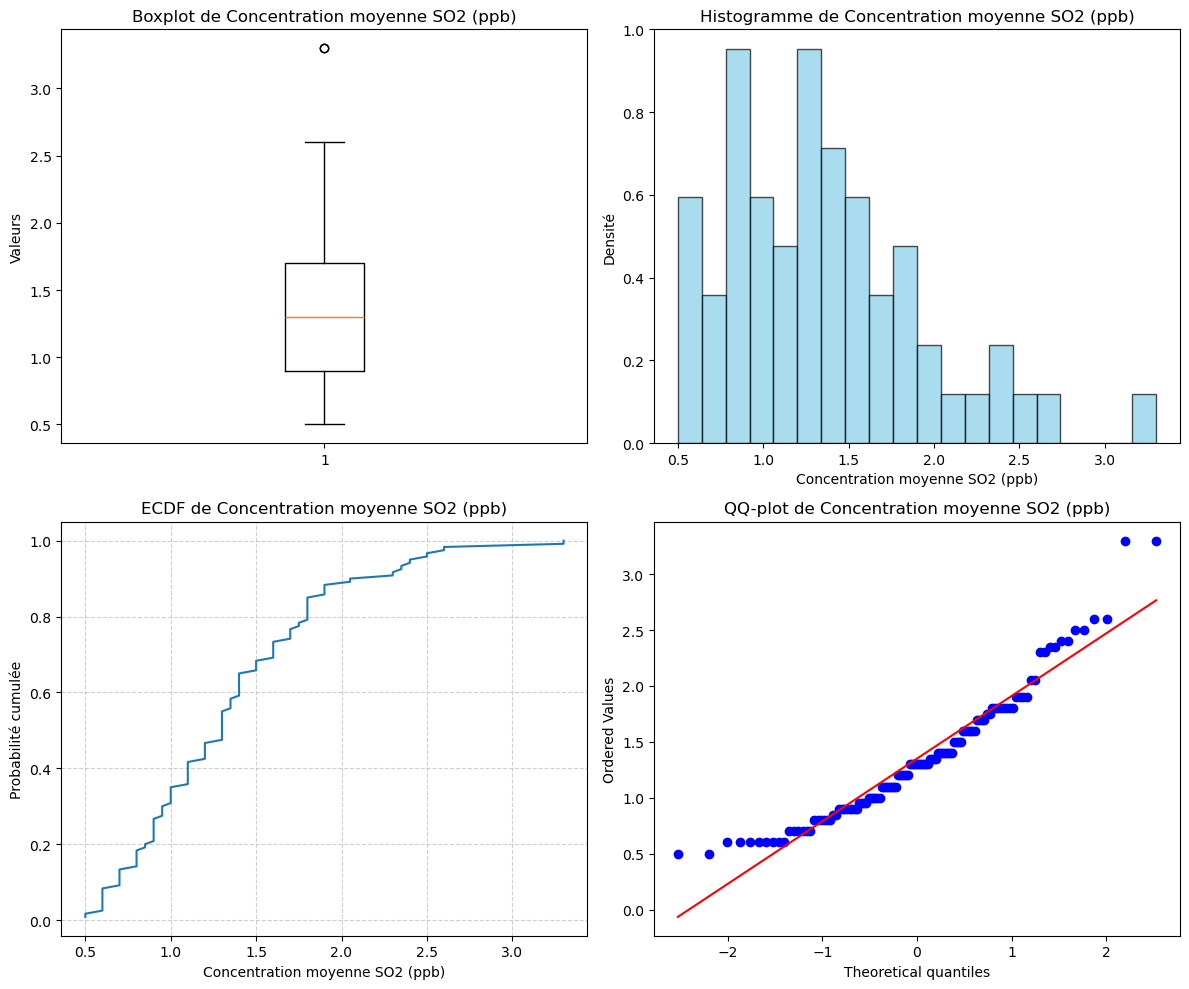

In [ ]:
# Passant à la variable : Concentration moyenne SO2 (ppb)
x = df_maladies_pollution_air["Concentration moyenne SO2 (ppb)"]
reps_graphiques_vars(x)

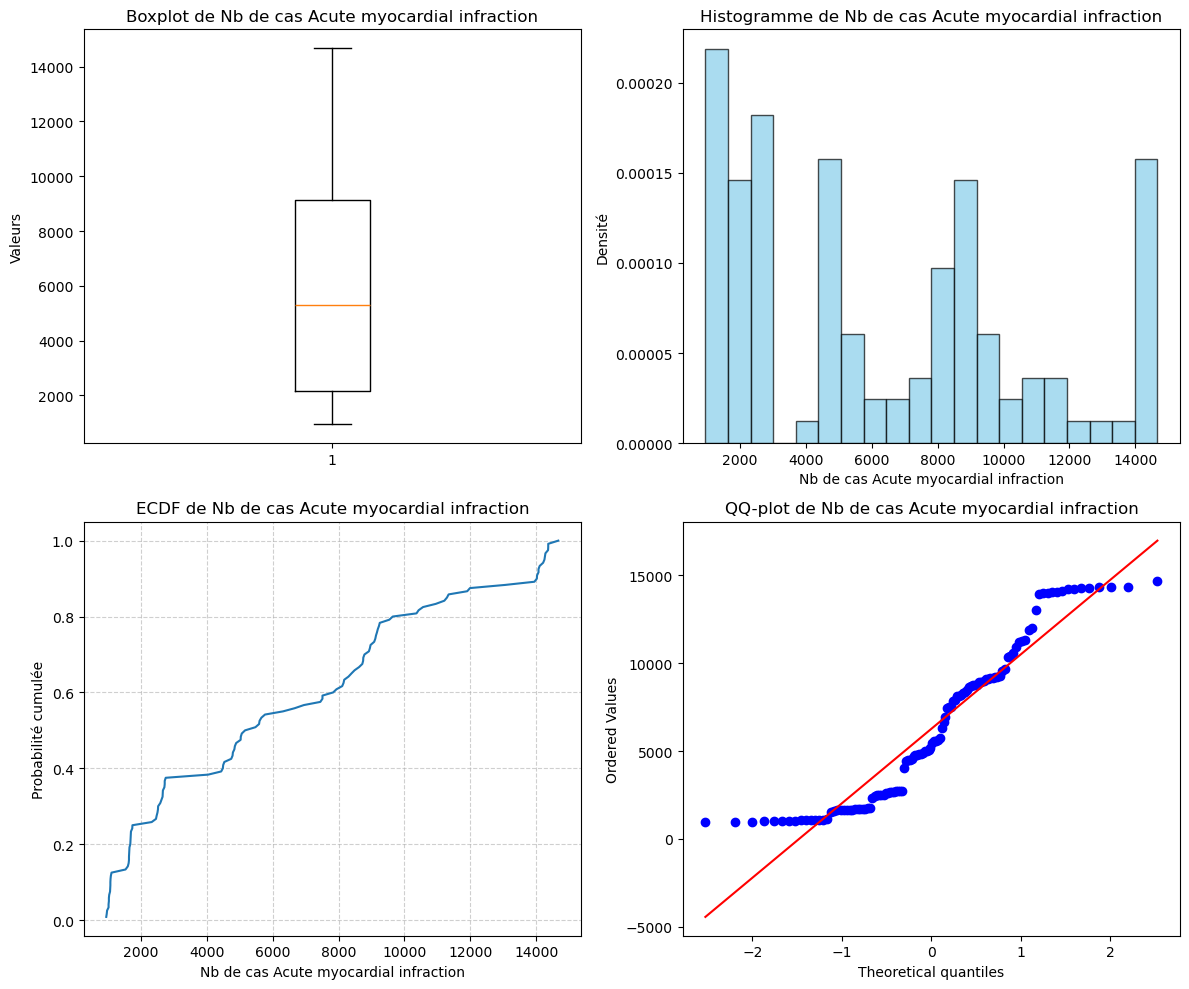

In [ ]:
# Passant à la variable : Nb de cas Acute myocardial infraction
x = pd.to_numeric(
    df_maladies_pollution_air["Nb de cas Acute myocardial infraction"],
    errors="coerce"
)
x = x.dropna()

reps_graphiques_vars(x)

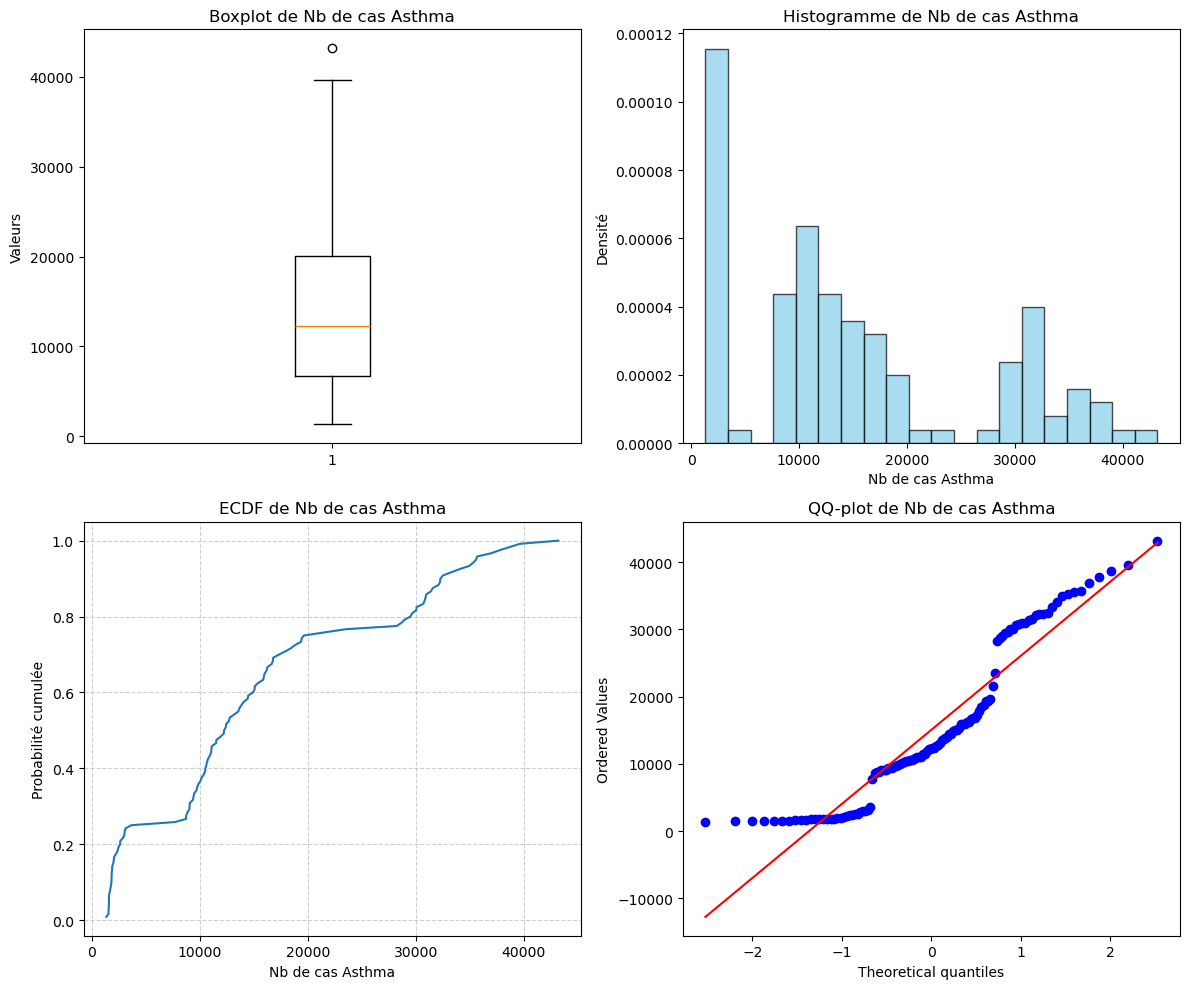

In [ ]:
# Passant à la variable : Nb de cas Asthma
x = pd.to_numeric(
    df_maladies_pollution_air["Nb de cas Asthma"],
    errors="coerce"
)
x = x.dropna()

reps_graphiques_vars(x)

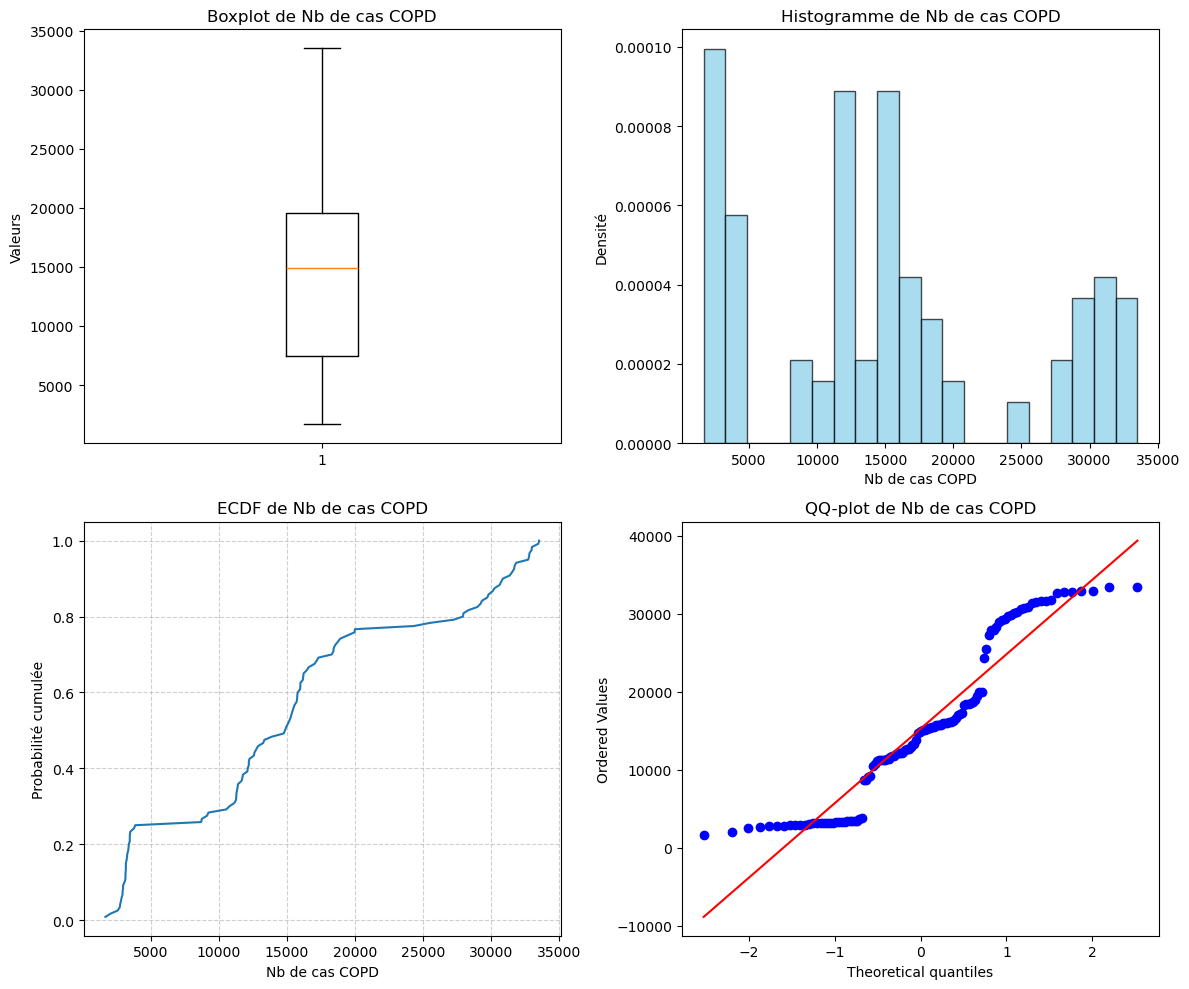

In [ ]:
# Passant à la variable : Nb de cas COPD
x = pd.to_numeric(
    df_maladies_pollution_air["Nb de cas COPD"],
    errors="coerce"
)
x = x.dropna()

reps_graphiques_vars(x)

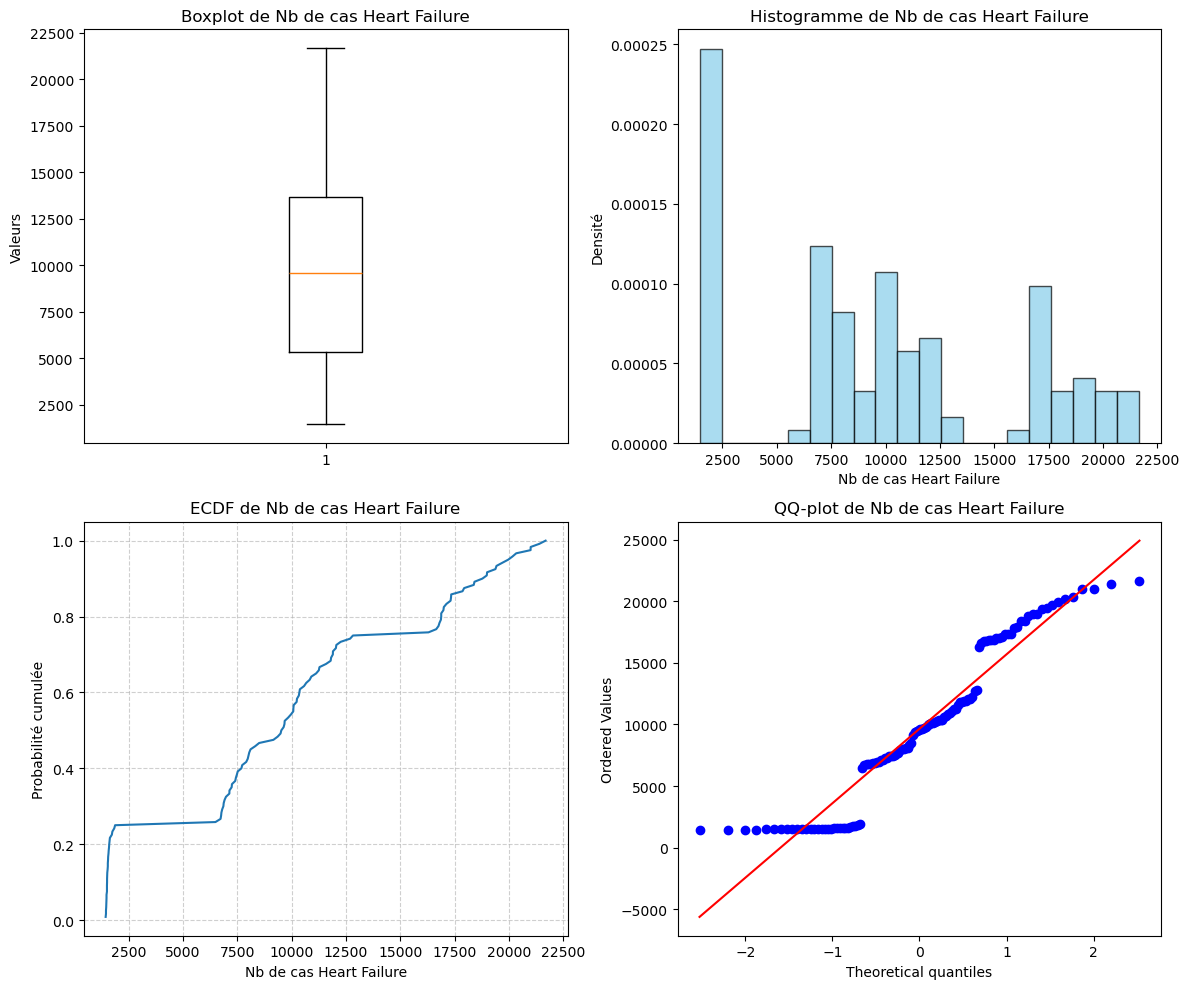

In [ ]:
# Passant à la variable : Nb de cas Heart Failure
x = pd.to_numeric(
    df_maladies_pollution_air["Nb de cas Heart Failure"],
    errors="coerce"
)
x = x.dropna()

reps_graphiques_vars(x)

#### Interpretation des graphiques (Nb de cas Heart Failure) : 
Boxplot :
* Le nombre de cas d’insuffisance cardiaque est centré autour de ~9 500–10 000 cas.
* La dispersion est élevée, avec un intervalle interquartile large.
* Présence de valeurs extrêmes importantes.
* Distribution clairement asymétrique à droite.

Histogramme :
* La distribution est fortement asymétrique à droite.
* Une grande concentration de valeurs faibles, et quelques valeurs très élevées.

ECDF :
* Environ 25 % des observations sont inférieures à ~2 000 cas.
* La progression n’est pas régulière : on observe des paliers, traduisant des groupes distincts.
* Les valeurs élevées contribuent fortement à la queue de distribution.

QQ-plot :
* Forte déviation par rapport à la droite théorique.
* Écarts marqués dans les queues et au centre.
* La distribution ne suit pas une loi normale.

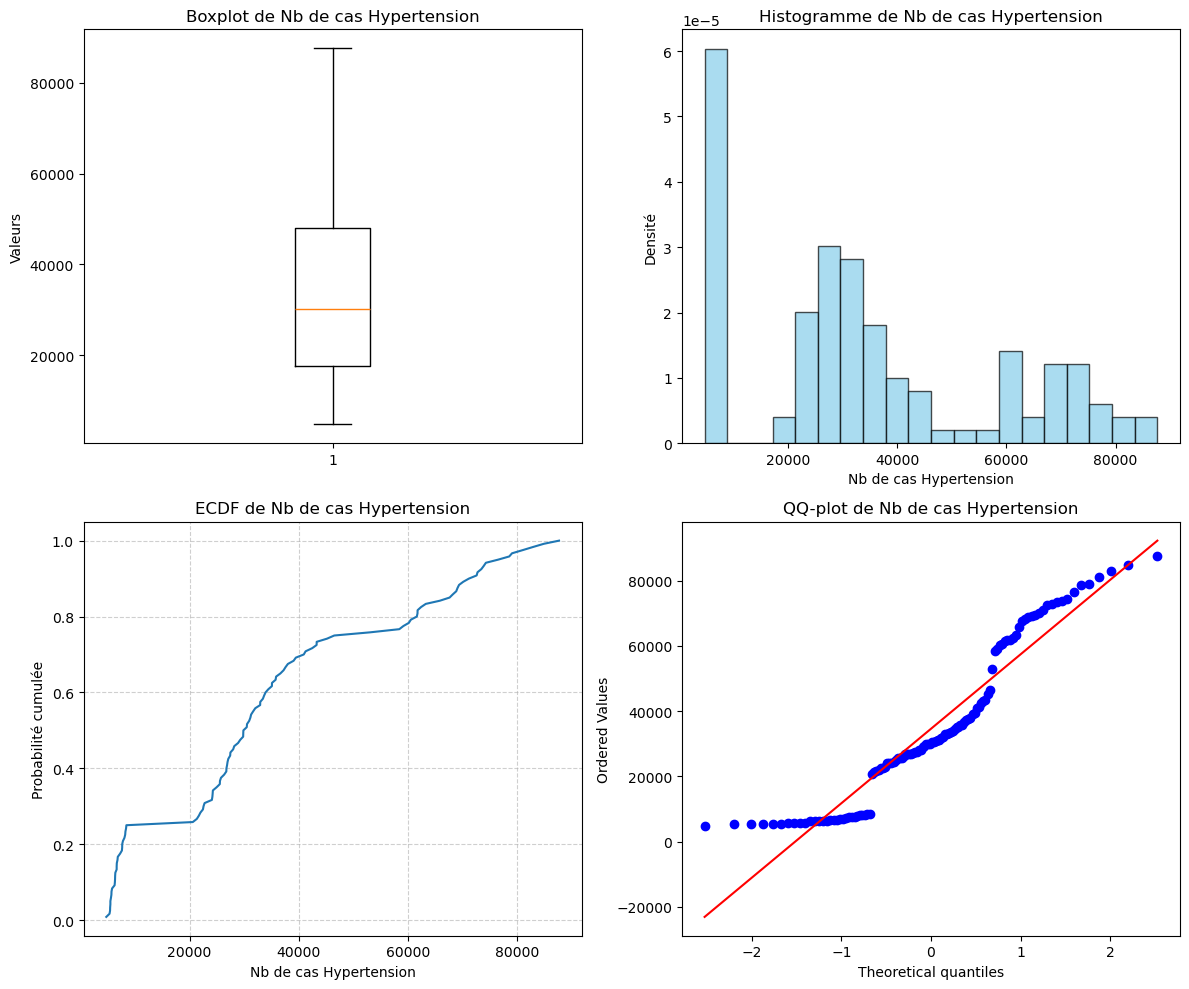

In [ ]:
# Passant à la variable : Nb de cas Hypertension
x = pd.to_numeric(
    df_maladies_pollution_air["Nb de cas Hypertension"],
    errors="coerce"
)
x = x.dropna()

reps_graphiques_vars(x)

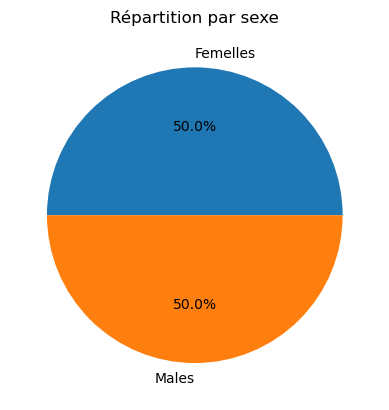

In [ ]:
# Pour la variable catégorique nominale : Sexe
# On utilise un diagramme circulaire pour vérifier si on a autant de lignes (individus) qui concernent les femmes que ceux qui concernent les hommes
df_maladies_pollution_air["Sexe"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("")
plt.title("Répartition par sexe")
plt.show()

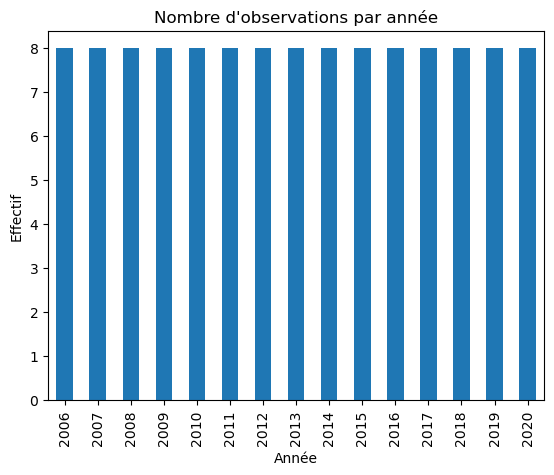

In [ ]:
# Même si la variable Année est numérique, en analyse 1D on la traite comme catégorique.
# On représente par un diagramme en barres le nombre de lignes (individus) par année afin de vérifier s'il y a des années manquantes ou sous-repésentées
df_maladies_pollution_air["Année"].value_counts().sort_index().plot(kind="bar")
plt.title("Nombre d'observations par année")
plt.xlabel("Année")
plt.ylabel("Effectif")
plt.show()

## Analyse Bidimensionnelle :

### Analyse de l'évolution temporelle du taux de maladie et de la concentration des polluants

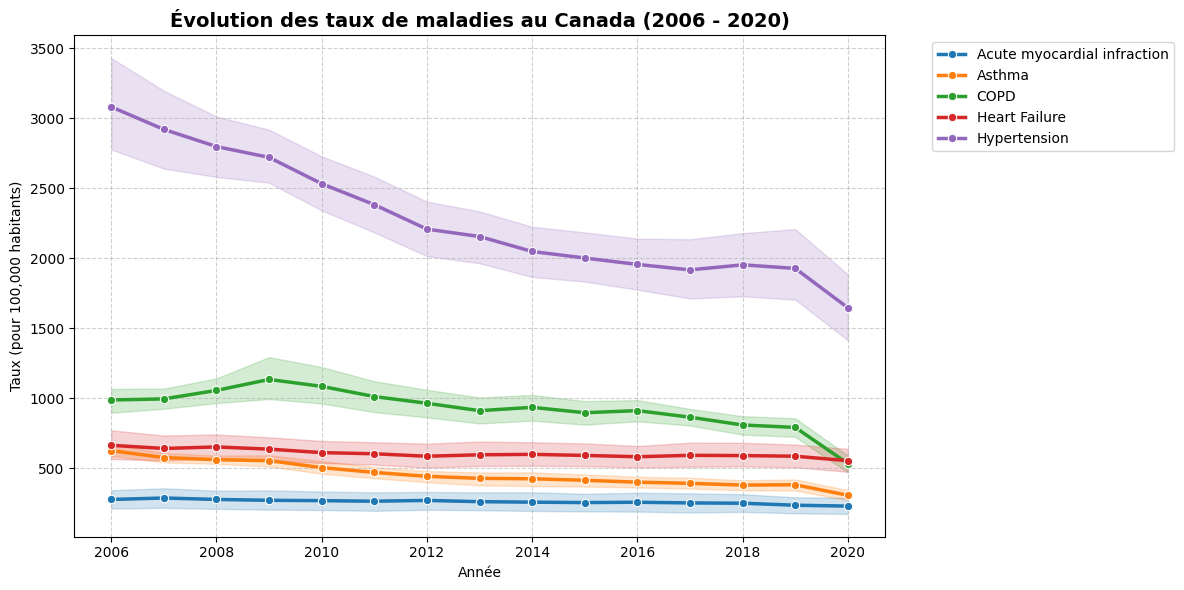

In [ ]:
# Passage au format long pour le graph

polluants = [c for c in df_maladies_pollution_air.columns if "Concentration moyenne" in c]
taux_maladie = [c for c in df_maladies_pollution_air.columns if "Taux (par 100,000)" in c]

df_plot = df_maladies_pollution_air.copy()
df_plot[polluants + taux_maladie] = df_plot[polluants + taux_maladie].apply(pd.to_numeric, errors='coerce').astype(float)


df_long_time = df_plot.melt(
    id_vars=['Année'], 
    value_vars=taux_maladie, 
    var_name='Maladie', 
    value_name='Taux'
)

# Nettoyage des noms de maladies pour la légende (on enlève le préfixe inutile)
df_long_time['Maladie'] = df_long_time['Maladie'].str.replace("Taux (par 100,000) ", "", regex=False)

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_long_time, x='Année', y='Taux', hue='Maladie', marker='o', linewidth=2.5)
plt.title("Évolution des taux de maladies au Canada (2006 - 2020)", fontsize=14, fontweight='bold')
plt.ylabel("Taux (pour 100,000 habitants)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Interprétations

- La baisse globale de l'Hypertension : c'est la courbe la plus haute. On voit qu'en 2006, on était à plus de $3000$ cas pour $100\ 000$ habitants, alors qu'en 2020 on tombe à environ $1600$. C'est une chute spectaculaire! Ça montre que la santé publique s'améliore globalement, peut-être grâce à de meilleurs traitements ou une meilleure prévention.
- L'Asthme se porte mieux aussi : le taux a été quasiment divisé par deux en 15 ans ($625 \rightarrow 306$). C'est un point clé : si on voit plus tard que la pollution baisse aussi, on aura une piste sérieuse de corrélation temporelle.
- Le "casse-tête" de la MPOC (COPD) : On remarque que la maladie a progressé entre 2006 et 2009 avant d'amorcer une lente descente. C'est une maladie chronique qui met du temps à se déclarer, donc ce pic pourrait être l'héritage d'une pollution passée.
- Le choc de 2020 : Toutes les maladies chutent brusquement entre 2019 et 2020. On est en plein COVID-19 : les gens allaient peut-être moins consulter, ou les systèmes de santé étaient saturés et ont moins bien reporté ces cas chroniques. C'est une "donnée aberrante" qu'il faudra garder en tête pour nos modèles de prédiction.

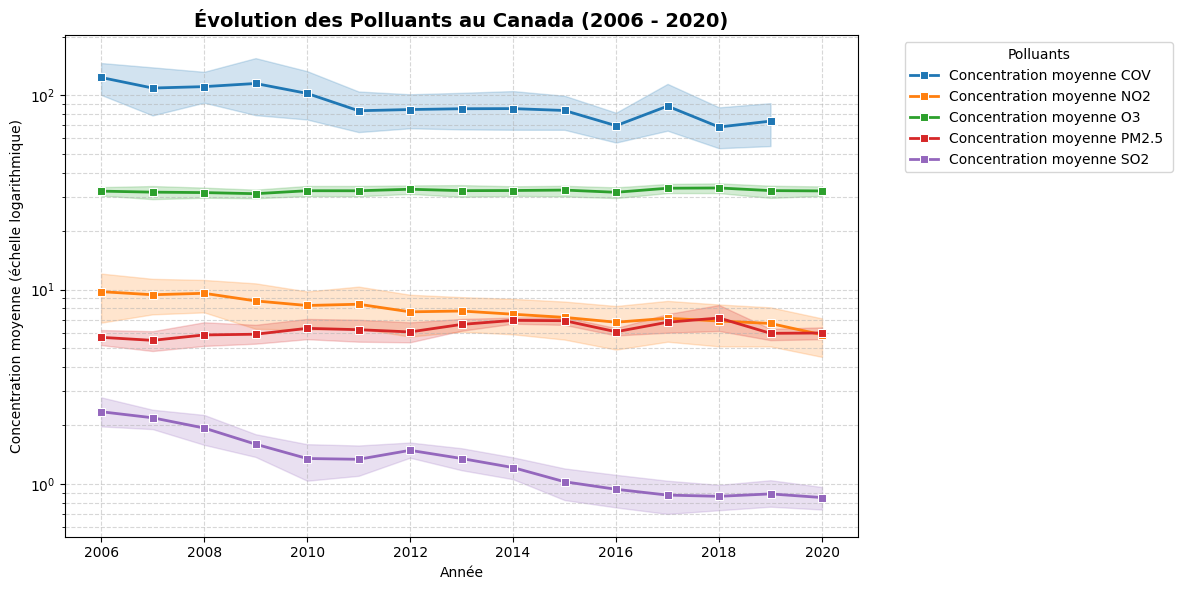

In [ ]:
# Passage au format long pour le graph

polluants = [c for c in df_maladies_pollution_air.columns if "Concentration moyenne" in c]
taux_maladie = [c for c in df_maladies_pollution_air.columns if "Taux (par 100,000)" in c]

df_plot = df_maladies_pollution_air.copy()
df_plot[polluants + taux_maladie] = df_plot[polluants + taux_maladie].apply(pd.to_numeric, errors='coerce').astype(float)

df_long_time = df_plot.melt(
    id_vars=['Année'], 
    value_vars=polluants, 
    var_name='Polluant', 
    value_name='Concentration moyenne'
)

# Nettoyage des noms de polluants pour la légende (on enlève le préfixe inutile)
df_long_time['Polluant'] = df_long_time['Polluant'].str.split('(').str[0].replace("Concentration moyenne ", "", regex=False)

# Tracé des courbes

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_long_time, x='Année', y='Concentration moyenne', hue='Polluant', marker='s', linewidth=2)

plt.yscale('log') # Indispensable pour voir tous les polluants ensemble
plt.title("Évolution des Polluants au Canada (2006 - 2020)", fontsize=14, fontweight='bold')
plt.ylabel("Concentration moyenne (échelle logarithmique)")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(title="Polluants", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Interprétations

La chute spectaculaire du $SO_2$ et du $NO_2$ : C'est le point le plus frappant. Le dioxyde de soufre ($SO_2$) a été divisé par presque 3 en 15 ans. C'est souvent le résultat des normes industrielles plus strictes. Si tu te souviens de notre analyse 2D, le $SO_2$ était très corrélé à l'Asthme... et comme l'asthme a aussi chuté sur la même période, on a ici une corrélation visuelle très forte.Les COV en baisse constante : Eux aussi diminuent régulièrement. Comme ils étaient liés à la MPOC (COPD) dans nos nuages de points, cette baisse explique sans doute pourquoi les nouveaux cas de maladies pulmonaires chroniques commencent à diminuer après 2010.La stabilité de l'Ozone ($O_3$) : Contrairement aux autres, l'ozone ne baisse pas vraiment, il oscille. C'est un polluant complexe qui dépend beaucoup de la météo (chaleur). Cela explique pourquoi il n'avait pas de lien clair avec la baisse des maladies dans nos analyses précédentes.Le mystère des $PM_{2.5}$ : On voit que les particules fines ont même eu tendance à augmenter légèrement vers 2017-2018 (probablement à cause des étés marqués par des feux de forêt intenses au Canada).

Maintenant qu'on a visualisé la baisse simultanée de la pollution et des maladies, cherchons à quantifier ce lien. Existe-t-il une corrélation directe entre un polluant spécifique et une pathologie précise ?

### Analyse des corrélations entre variables numériques.

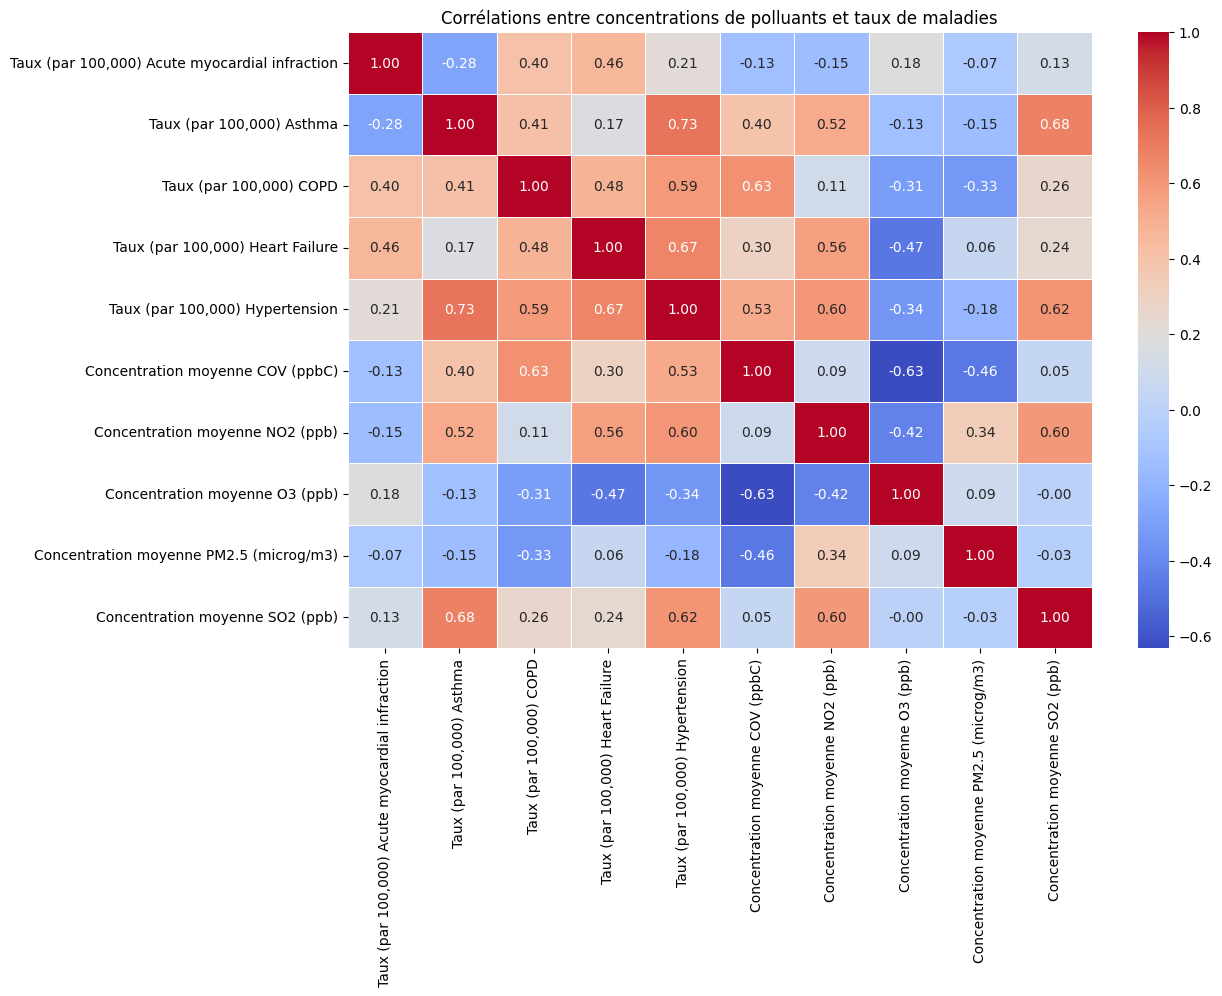

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# On sélectionne les colonnes numériques (Taux de maladies et Concentrations de polluants)
cols_analysees = [c for c in df_maladies_pollution_air.columns if 'Taux' in c or 'Concentration' in c]
# On calcule la matrice de corrélation des colonnes sélectionnées
corr_matrix = df_maladies_pollution_air[cols_analysees].corr()

# Affichage de la heatmap des corrélations pour identifier les relations pertinentes entre polluants et maladies
plt.figure(figsize = (12, 8))
sns.heatmap(corr_matrix, annot = True, cmap = 'coolwarm', fmt = ".2f", linewidths = 0.5)
plt.title("Corrélations entre concentrations de polluants et taux de maladies")
plt.show()

#### Interprétations

Cet Heatmap nous donne une vue d'ensemble des potentielles corrélations entre les différentes variables numériques du dataset. Plus la valeur est proche de 1 ou -1 plus la corrélation est forte et la coloration est très chaude (rouge foncé) ou très froide (bleu foncé).

En observant le graphique ci-dessus, on remarque qu'il existe des relations même entre maladies (ex. Hypertension et Asthme à 0.73) mais on va plutôt orienter notre analyse sur les relations entre "concentration de polluant dans l'air" et "présence des maladies dans la population". On constate qu'il y a une corrélation potentielle entre les couples de variables SO2 et Asthme (0.68), COV et COPD (0.63), NO2 et Heart failure (0.56), NO2 et Hypertension (0.60) et SO2 et Hypertension (0.62). Dans la suite, on va visualiser ces relations afin de confirmer qu'il existe bien une corrélation linéraire entre les variables citées.

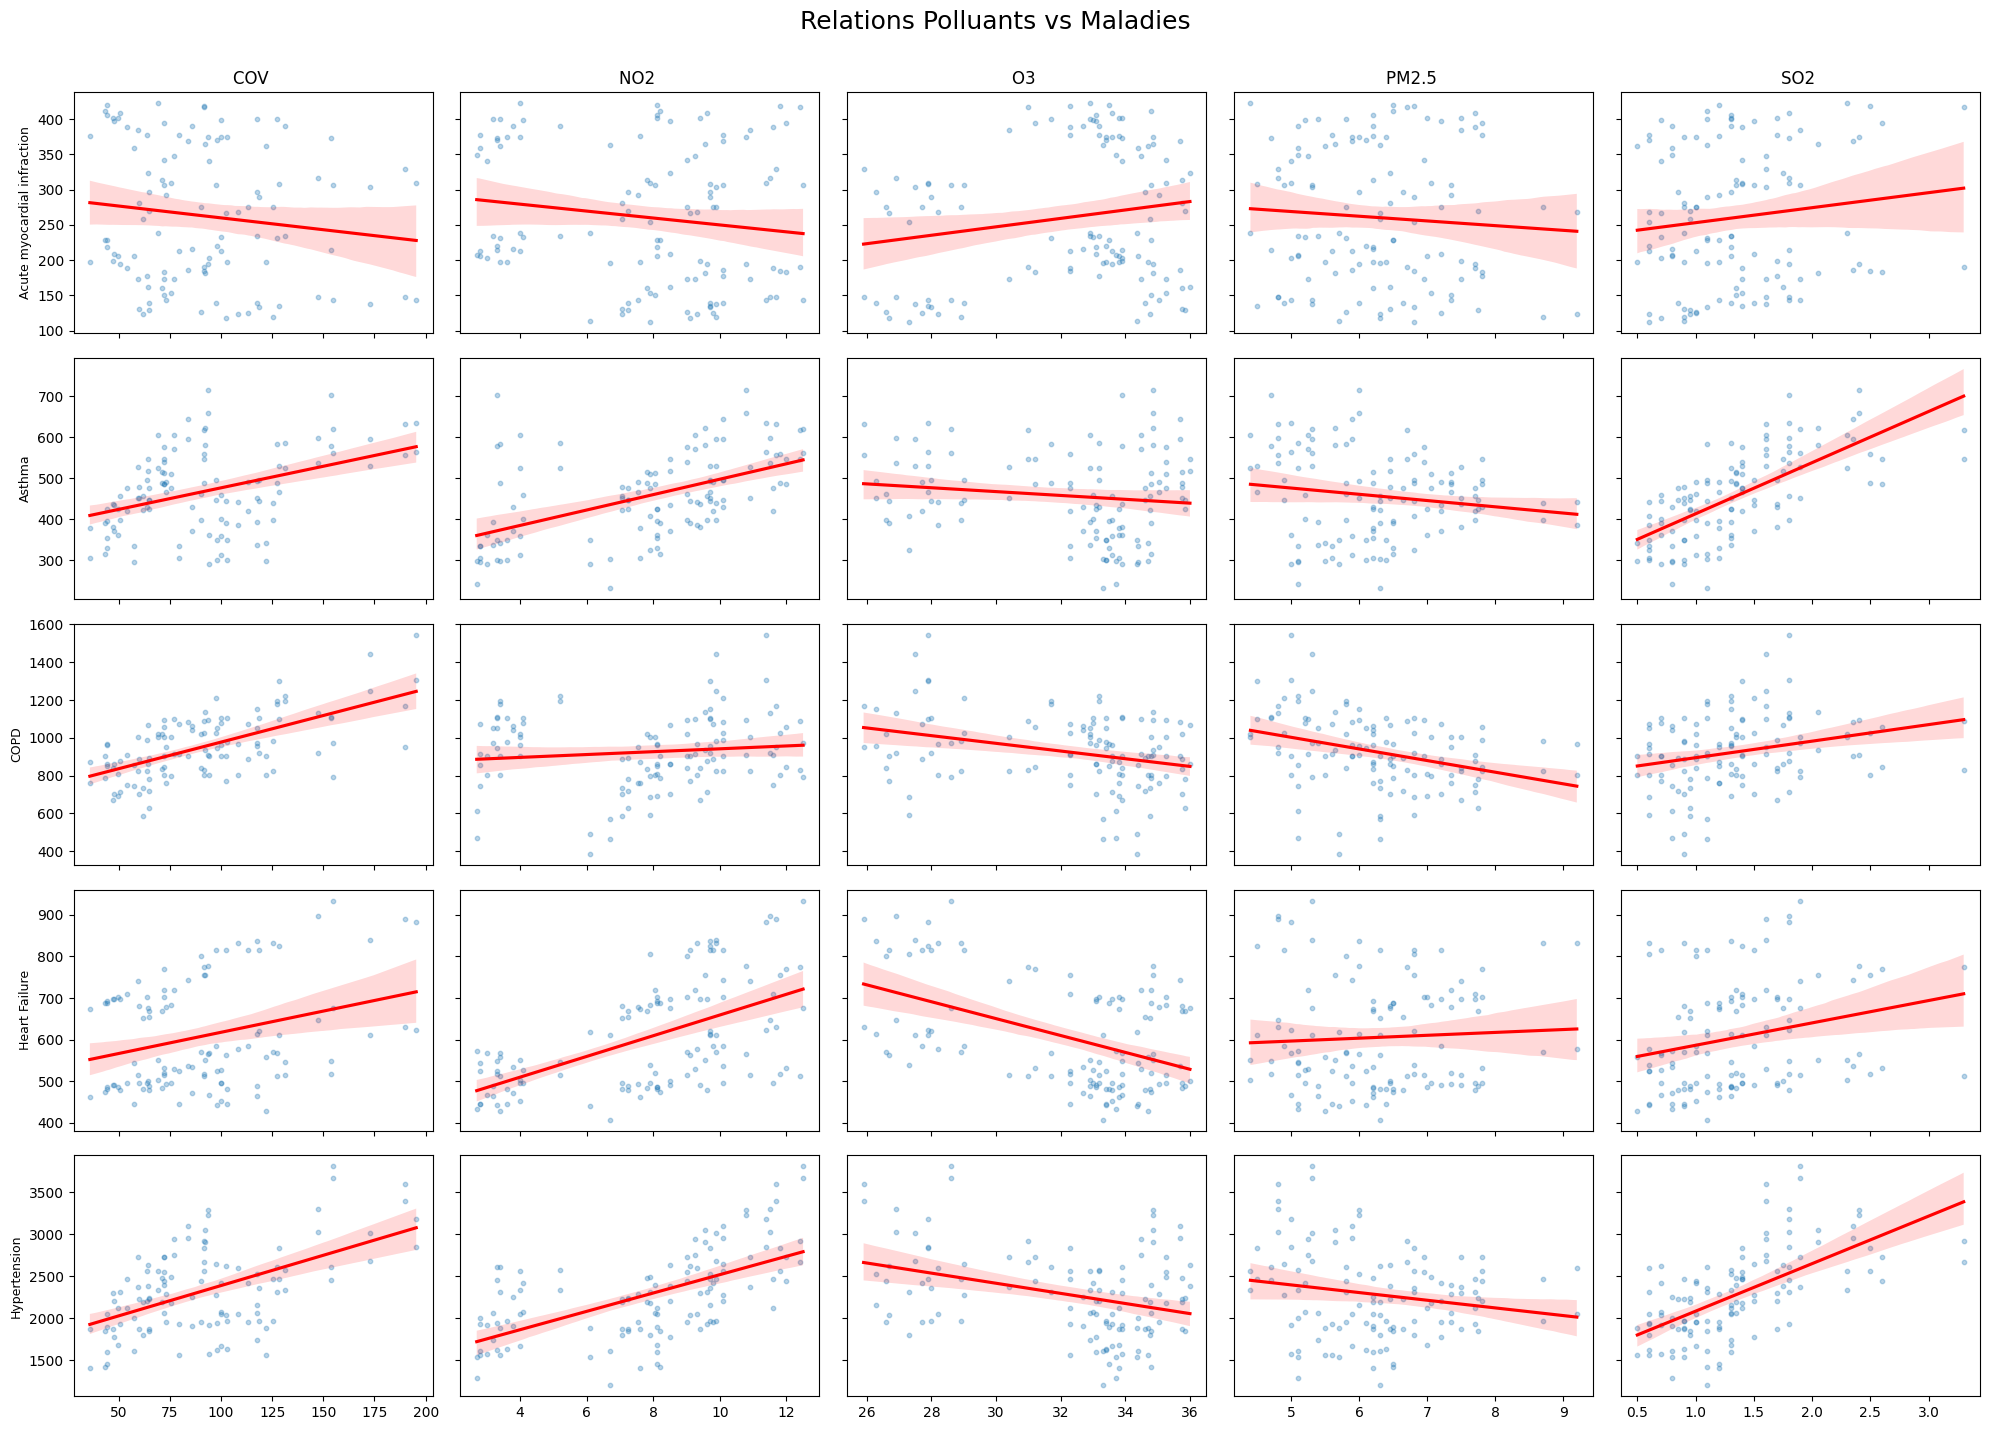

In [ ]:
# Configuration de la grille
fig, axes = plt.subplots(len(taux_maladie), len(polluants), figsize=(20, 15), sharex='col', sharey='row')

for i, mal in enumerate(taux_maladie):
    for j, pol in enumerate(polluants):
        # On trace le graph sur l'axe correspondant
        sns.regplot(data=df_plot, x=pol, y=mal, ax=axes[i, j], 
                    scatter_kws={'alpha':0.3, 's':10}, line_kws={'color':'red'})
        
        # Simplification des titres et labels
        # On ne met le titre que sur la première ligne
        if i == 0: axes[i, j].set_title(pol.split('(')[0].replace("Concentration moyenne ", ""))
        
        # On ne met le label Y que sur la première colonne
        if j == 0: axes[i, j].set_ylabel(mal.replace("Taux (par 100,000) ", ""), fontsize=9)
        else:
            axes[i, j].set_ylabel('') # On enlève le label pour les colonnes suivantes
            
        # On nettoie les labels inutiles pour alléger le visuel
        axes[i, j].set_xlabel('') 

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.suptitle("Relations Polluants vs Maladies", fontsize=18)
plt.show()

#### Interprétations

En regardant les scatter plots et les coefficients, on peut tirer quelques conclusions intéressantes pour notre étude :
- Le $SO_2$ et le $NO_2$ sont les plus fréquents dans les relations polluant-maladie. On voit une relation linéaire assez nette entre le dioxyde de soufre ($SO_2$) et l'Asthme (0.68) ainsi qu'avec l'Hypertension (0.62). C'est cohérent avec la littérature médicale : ce sont des gaz irritants qui déclenchent des crises respiratoires. De même, le $NO_2$ (souvent lié au trafic routier) semble très corrélé à l'Hypertension (0.60) et aux problèmes cardiaques (0.56). 
- Les COV et les maladies chroniques : les composés organiques volatils (COV) montrent une corrélation forte avec la MPOC (COPD) à 0.63. C'est un insight intéressant, car cela suggère que la pollution industrielle ou domestique a un impact de long terme sur la capacité pulmonaire des populations étudiées.
- Le paradoxe de l'Ozone ($O_3$) : on remarque des corrélations négatives et très faible. Ce n'est pas que l'ozone est "bon" pour la santé, mais plutôt un phénomène chimique classique : en ville, le $NO$ émis par les voitures "consomme" l'ozone local. Donc, là où il y a beaucoup de trafic (et donc plus de maladies), l'ozone est parfois plus bas.
- Le cas des $PM_{2.5}$ : les particules fines montrent des corrélations très faibles ici. Cela peut s'expliquer par le fait que leurs pics sont souvent très localisés ou saisonniers (feux de forêt, chauffage au bois), ce qui peut être lissé par nos moyennes annuelles.
- L'hypertension semble être la pathologie la plus sensible à la qualité de l'air globale. Contrairement à l'Asthme qui est très ciblé sur le $SO_2$, l'hypertension montre des corrélations élevées et constantes.
- L'infarctus (Acute myocardial infarctus) ne semble pas corrélé aux moyennes annuelles de pollution.

### Analyse des corrélations entre variables catégoriques et numériques

L'analyse précédente a révélé des liens numériques forts entre certains polluants et les maladies. Cependant, la pollution n'affecte pas tout le monde de la même manière. Dans cette section, nous explorons si des facteurs démographiques comme le Sexe ou la Région agissent comme des déterminants pour ces maladies, afin d'identifier les populations les plus vulnérables.

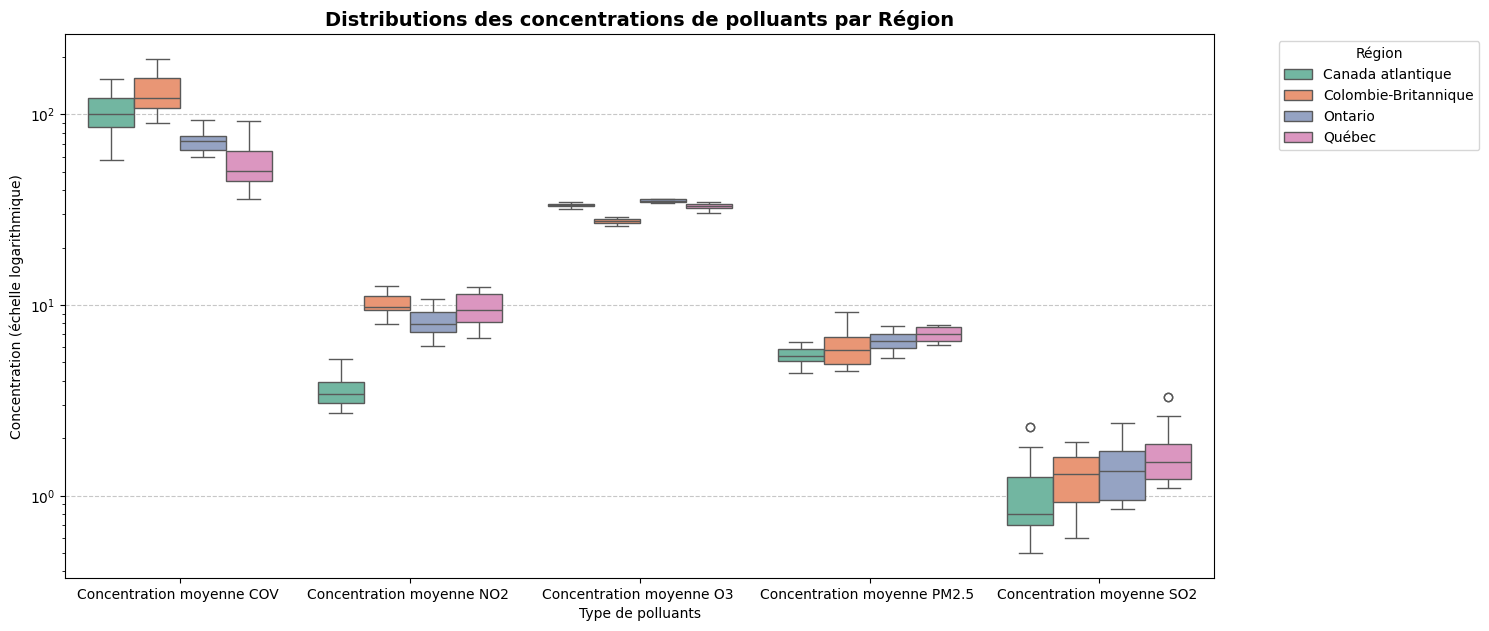

In [ ]:
# --- ANALYSE DE LA POLLUTION PAR RÉGION ---

# 1. On "fond" le DataFrame pour avoir une colonne 'Polluant' et une colonne 'Concentration'
# Cela permet de comparer toutes les distributions de polluant d'un coup avec le paramètre 'hue'
df_long_polluants = df_plot.melt(
    id_vars = ['Région', 'Année'], 
    value_vars = polluants,
    var_name = 'Polluant', 
    value_name = 'Concentration'
)

# Nettoyage des noms de polluants pour la légende (on enlève le préfixe inutile)
df_long_polluants['Polluant'] = df_long_polluants['Polluant'].str.split('(').str[0].replace("Concentration moyenne ", "", regex=False)

# 2. Création des graphiques
plt.figure(figsize=(15, 12))


# Distribution des concentrations de polluants par RÉGION
# On utilise 'hue' pour différencier les polluants au sein de chaque région
plt.subplot(2, 1, 1)
sns.boxplot(data=df_long_polluants, x='Polluant', y='Concentration', hue='Région', palette="Set2")
plt.yscale('log') # permet de voir clairement les COV et les autres polluants sur le même graphique
plt.ylabel("Concentration (échelle logarithmique)")
plt.xlabel("Type de polluants")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.title("Distributions des concentrations de polluants par Région", fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Région", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#### Interprétations

L'utilisation d'une échelle logarithmique est ici indispensable car les concentrations de COV (en ppbC) sont massivement plus élevées que celles du $SO_2$ ou des $PM_{2.5}$. Sans cela, les autres polluants seraient invisibles sur le graphique.

Le $NO_2$ : le polluant le plus discriminant pour la Colombie-Britannique est sans conteste le $NO_2$. Sa boîte est située au-dessus de toutes les autres régions, avec une médiane nettement supérieure. 

Le $SO_2$ : à l'opposé, pour le dioxyde de soufre ($SO_2$), la tendance s'inverse. Les boîtes du Québec et de l'Ontario sont positionnées plus haut et présentent des moustaches supérieures très étirées. Cela traduit une pollution de type industrielle beaucoup plus présente, contrastant avec la pureté relative de l'air en Colombie-Britannique pour ce polluant spécifique.

Le ($O_3$) : les médianes de l'ozone sont relativement proches entre les régions. Cependant, on remarque que là où le $NO_2$ est le plus fort (Colombie-Britanique), l'ozone a tendance à avoir une distribution plus resserrée. C'est un phénomène chimique classique : le monoxyde d'azote urbain NO 'consomme' l'ozone localement. 

$PM_{2.5}$ et COV : pour les particules fines ($PM_{2.5}$) et les composés organiques volatils (COV), les distributions sont plus alignées d'une région à l'autre. On note toutefois une dispersion importante (boîtes larges) pour les COV au Canada Atlantique et en Colombie-Britanique, ce qui suggère des sources d'émissions très variables selon les années ou les saisons (chauffage au bois, feux de forêt ou activités portuaires).



Cette cartographie des polluants nous montre deux visages du Canada : un Ouest marqué par le $NO_2$ (transport) et un Est marqué par le $SO_2$ (industrie). Si l'hypothèse est juste, on doit retrouver ces 'signatures' dans la prévalence des maladies : l'insuffisance cardiaque devrait suivre la trace du $NO_2$ en Colombie-Britanique, tandis que l'asthme et l'hypertension pourraient être plus liés au passé industriel de l'Ontario et du Québec.

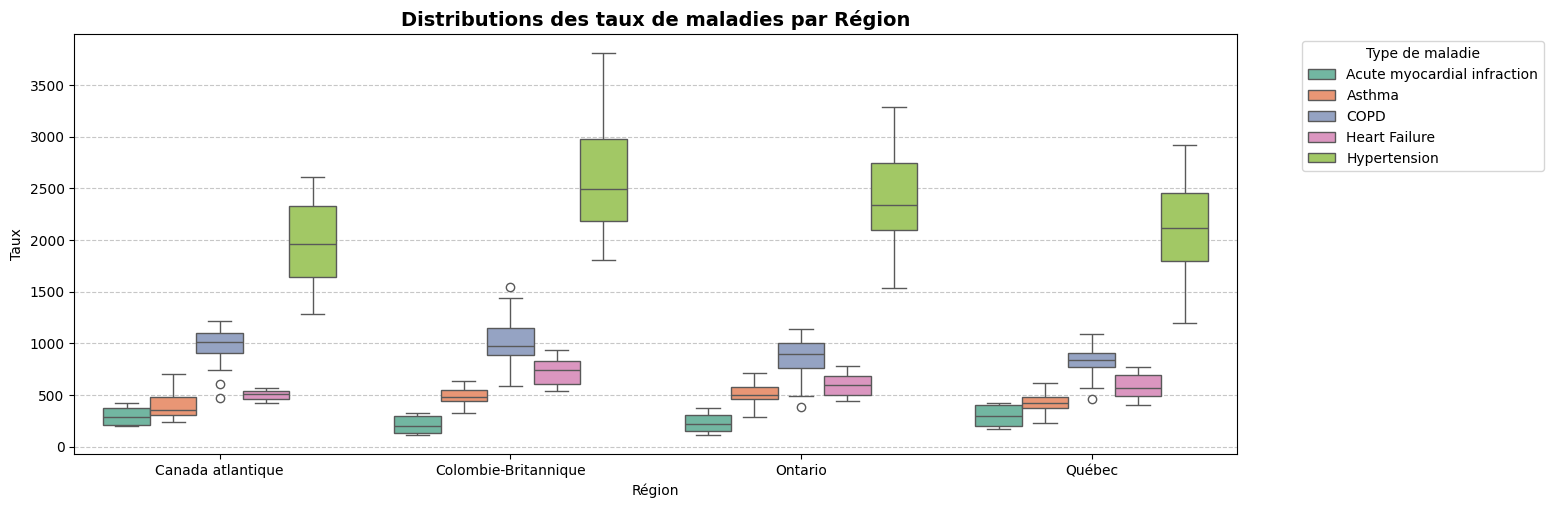

In [ ]:
# Distribution des taux de maladie par RÉGION

# 1. On "fond" le DataFrame pour avoir une colonne 'Maladie' et une colonne 'Taux'
# Cela permet de comparer toutes les distributions de maladie d'un coup avec le paramètre 'hue'
df_long_maladies = df_plot.melt(
    id_vars = ['Région', 'Sexe'], 
    value_vars = taux_maladie,
    var_name = 'Maladie', 
    value_name = 'Taux'
)

# Nettoyage des noms de maladies pour la légende (on enlève le préfixe inutile)
df_long_maladies['Maladie'] = df_long_maladies['Maladie'].str.replace("Taux (par 100,000) ", "", regex=False)

# 2. Création des graphiques
plt.figure(figsize=(15, 12))

# On utilise 'hue' pour différencier les maladies au sein de chaque région
plt.subplot(2, 1, 1)
sns.boxplot(data=df_long_maladies, x='Région', y='Taux', hue='Maladie', palette="Set2")
plt.title("Distributions des taux de maladies par Région", fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Type de maladie", bbox_to_anchor=(1.05, 1), loc='upper left')

#### Interprétation

L'Hypertension : l'hypertension domine visuellement le graphique avec les boîtes les plus étirées verticalement dans les quatre régions. Cette grande dispersion confirme que la baisse des taux constatée entre 2006 et 2020 est un phénomène national et non local. On note cependant que la médiane de l'Ontario et du Québec semble légèrement plus haute que celle du Canada Atlantique, suggérant une prévalence plus marquée dans les provinces les plus peuplées.

Asthme : les médianes de l'asthme sont pratiquement alignées d'une région à l'autre, ce qui suggère une base de prévalence commune à tout le pays. 

Insuffisance cardiaque : elle présente une médiane nettement plus élevée en Colombie-Britannique que dans les autres provinces. La boîte est située plus haut sur l'axe des ordonnées, ce qui en fait un 'point chaud' pour cette maladie. C'est  cohérent avec les taux élevés de $NO_2$ présent dans la région, suggérant ainsi que la pollution en $NO_2$ pourrait être un facteur aggravant prédominant.

Infarctus : on remarque que le Québec et le Canada Atlantique présentent les moustaches supérieures les plus longues. Cela signifie que bien que la médiane soit comparable aux autres, ces régions ont des pics critiques. L'Ontario semble avoir une distribution plus 'tassée' vers le bas, indiquant une meilleure maîtrise ou une incidence plus faible.

COPD : la maladie pulmonaire obstructive chronique montre les boîtes les plus écrasées. Cette faible variabilité indique qu'elle ne subit pas de fluctuations annuelles brutales, quelle que soit la région. Le nuage de points reste concentré autour d'une médiane constante.

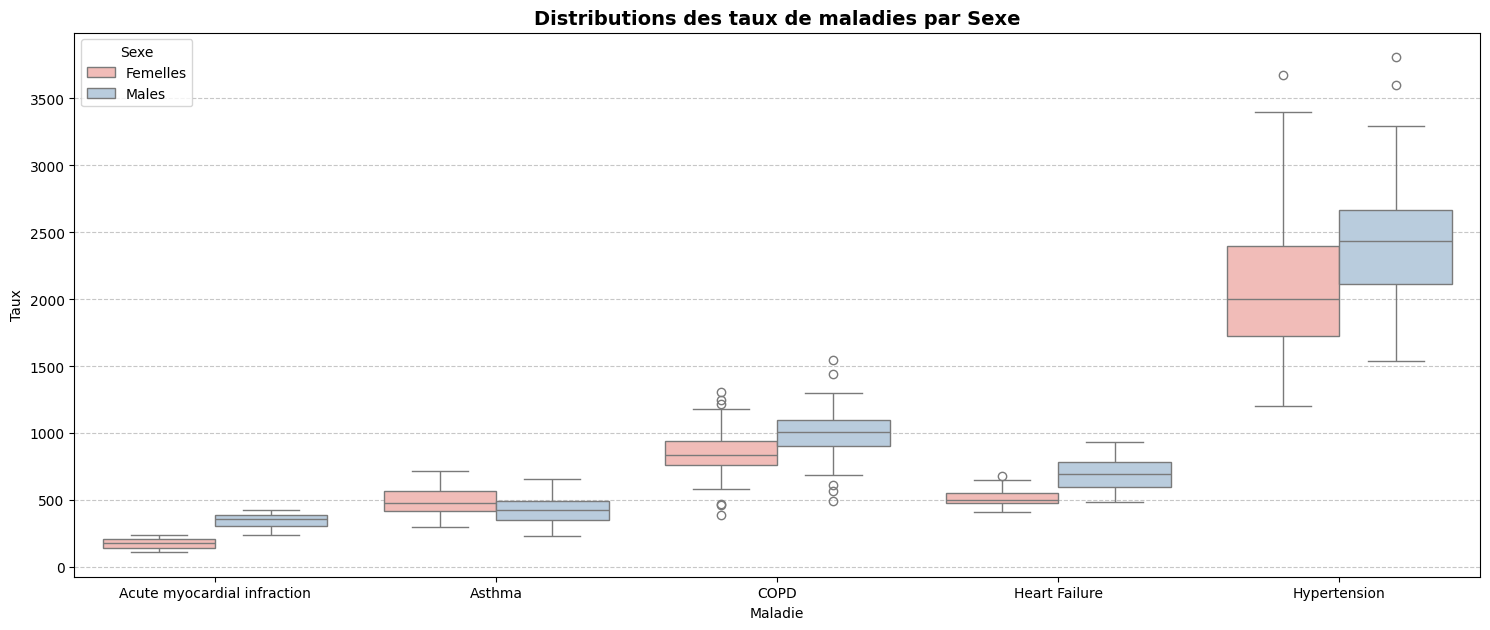

In [ ]:
# Distribution des taux de maladie par SEXE
# On inverse : on met les maladies en X et on compare Hommes/Femelles avec 'hue'
plt.figure(figsize=(15, 12))
plt.subplot(2, 1, 2)
sns.boxplot(data=df_long_maladies, x='Maladie', y='Taux', hue='Sexe', palette="Pastel1")
plt.title("Distributions des taux de maladies par Sexe", fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#### Interprétation

Asthme : pour l'asthme, les médianes des deux sexes sont très proches et les boîtes (l'écart interquartile) se recouvrent quasi intégralement. Cela suggère que, dans notre échantillon, le sexe n'est pas le facteur discriminant majeur par rapport à la région ou à l'année.

Maladies cardiaques : à l'inverse, pour l'infarctus (Acute myocardial infraction) et l'insuffisance cardiaque (Heart Failure), on observe un décalage vers le haut de la boîte des hommes. La moustache supérieure masculine atteint des niveaux bien plus élevés que celle des femmes, indiquant que les pics de risque cardiovasculaire concernent majoritairement les hommes.

Hypertension (dispersion commune) : l'hypertension montre les boîtes les plus étirées verticalement pour les deux sexes. Cette grande dispersion (longueur de la boîte) traduit la baisse des taux sur 15 ans(2006-2020), plutôt qu'une différence de genre. On note toutefois que le 'bas de la boîte' (le 1er quartile) est plus bas chez les femmes, signe d'une amélioration plus rapide ou plus marquée chez elles.

# Exploration du jeu de données
Pour ce faire, on utilisera des méthodes d'apprentissage non supervisés :
### Clustering par l'algorithme K-Means
C'est une méthode qui regroupe des données similaires en groupes (clusters) sans étiquettes préalables, révélant ainsi des structures cachées et des motifs dans les données. Parmi les algorithmes courants on trouve le K-Means (partitionnement en K groupes basés sur des centroïdes) et c'est ce qu'on va appliquer dans cette partie. 

Le K-Means est un algorithme qui regroupe des individus similaires, uniquement à partir de variables numériques, en se basant sur des distances (euclidiennes).

Il est donc indispensable de :
* Choisir les individus (ce qu’on regroupe),
* Sélectionner les variables numériques pertinentes,
* Standardiser les données,
* Choisir le nombre de clusters K,
* Interpréter les groupes obtenus.

**Remarque :** Si on applique K-Means sur le dataframe final, qui combine les taux de toutes les maladies, on aura une confusion sémantique (les clusters mélangeraient des profils de maladies très différentes ce qui rend impossible d’interpréter médicalement un cluster) et une dominance de certaines variables
(une maladie avec de grands taux ou grands volumes écrase les autres). D'où la décision de décomposer notre dataframe en cinq dataframes, un par maladie.

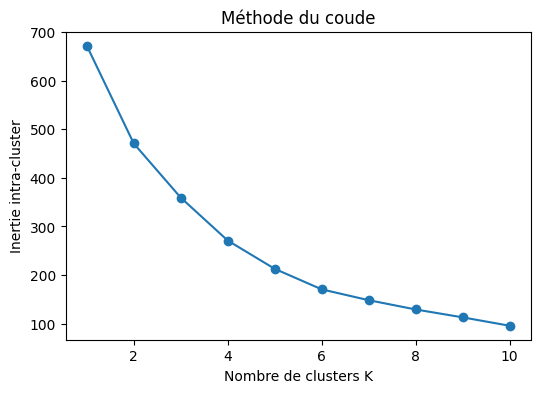

In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Dans notre cas un individu est une observation (Année, Région, Sexe) caractérisé par : un indicateur de santé (taux par 100,000)
# et des indicateurs de pollution atmosphérique.
# Pour les variables à selectionner : on va exclure les variables catégorielles (Année, Région, Sexe) 
# et on gardera les variables numériques pertinentes : Taux des maladies et Concentrations des polluants
# Remarque : il est préférable d’utiliser les taux plutôt que les nombres de cas, car les nombres de cas dépendent fortement de la population.

# On commence par la maladie asthme
colonnes_a_garder_asthme = [
    "Taux (par 100,000) Asthma",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X_asthme = df_maladies_pollution_air[colonnes_a_garder_asthme].dropna()

# K-Means est très sensible à l’échelle des variables. Les concentrations et les taux n’ont pas la même unité, donc on doit standardiser 
# (moyenne = 0 et écart-type = 1 pour chaque variable).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_asthme)

# Choix du nombre de clusters K par la méthode du coude :
inertia = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

In [56]:
# En prenant en compte la méthode du coude, on peut choisir la valeur K = 2
# Application de K-Means
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clustering = df_maladies_pollution_air.loc[X_asthme.index].copy()
df_clustering["Cluster"] = clusters

cluster_profile = (
    df_clustering
    .groupby("Cluster")[colonnes_a_garder_asthme]
    .mean()
)
cluster_profile

,"Taux (par 100,000) Asthma",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
Cluster,,,,,,
0,412.739656,75.104412,6.955882,33.464706,6.661765,1.119118
1,552.97295,116.861364,9.554545,30.329545,5.677273,1.797727


#### Interprétation : 

On a deux clusters : 
* Cluster 0 : Zones à pollution et asthme modérés.
* Cluster 1 : Zones à forte pollution et forte prévalence d'asthme.

Le résultat du K-Means obtenu suggère que dans notre jeu de données, l'asthme est plus fortement lié aux polluants chimiques gazeux (COV, SO2, NO2) qu'aux particules fines (PM2.5) ou à l'ozone.
Le passage du Cluster 0 au Cluster 1 montre qu'une augmentation combinée de ces gaz est associée à une hausse de 34% des cas d'asthme.

Le fait que les polluants O3 et PM2.5 soient plus bas dans le cluster où l'asthme est plus élevé est contre-intuitif. Cela peut signifier que ces deux polluants ne sont pas des facteurs déterminants ici.

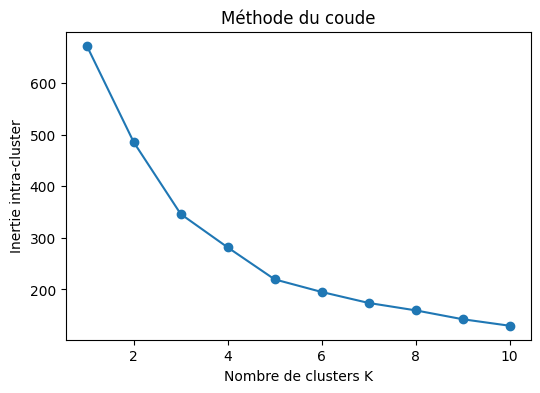

In [57]:
# Passant à la maladie COPD
colonnes_a_garder_copd = [
    "Taux (par 100,000) COPD",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X_copd = df_maladies_pollution_air[colonnes_a_garder_copd].dropna()

# K-Means est très sensible à l’échelle des variables. Les concentrations et les taux n’ont pas la même unité, donc on doit standardiser 
# (moyenne = 0 et écart-type = 1 pour chaque variable).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_copd)

# Choix du nombre de clusters K par la méthode du coude :
inertia = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

In [58]:
# En prenant en compte la méthode du coude, on peut choisir la valeur K = 3
# Application de K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clustering = df_maladies_pollution_air.loc[X_copd.index].copy()
df_clustering["Cluster"] = clusters

cluster_profile = (
    df_clustering
    .groupby("Cluster")[colonnes_a_garder_copd]
    .mean()
)
cluster_profile

,"Taux (par 100,000) COPD",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
Cluster,,,,,,
0,1010.224546,102.792857,3.564286,33.285714,5.457143,1.028571
1,1064.807692,134.273077,10.284615,27.503846,5.819231,1.342308
2,875.741379,66.891379,9.072414,33.844828,6.874138,1.577586


#### Interprétation
On a trois clusters :
* Cluster 1 : Zones Industrielles/Urbaines Denses et Santé critique : Ce cluster présente le taux de la maladie COPD le plus élevé, les concentrations les plus fortes en COV et en NO2 alors que le O3 présente sa valeur la plus basse dans ce cluster.
* Cluster 2 : Zones Particulaires et Santé Intermédiaire : Ce groupe a le taux de COPD le plus bas, malgré des niveaux élevés de certaines particules (comme les PM2.5 et le SO2).
* Cluster 0 : Profil "Bruit de Fond" : Ce cluster est paradoxal car il a un taux de COPD élevé, presque autant que le cluster critique alors que pour les polluants on a NO2 qui est très bas, tout comme le SO2. Cependant, les COV sont relativement présents.

Le résultat de K-Means montre que les COV sont les meilleurs indicateurs de la maladie COPD.

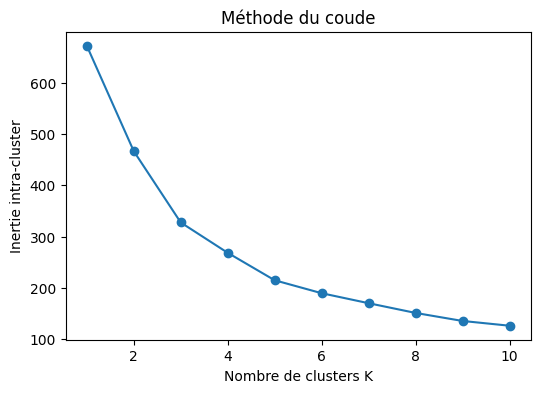

In [59]:
# Passant à la maladie d'insuffisance cardiaque
colonnes_a_garder_hf = [
    "Taux (par 100,000) Heart Failure",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X_hf = df_maladies_pollution_air[colonnes_a_garder_hf].dropna()

# K-Means est très sensible à l’échelle des variables. Les concentrations et les taux n’ont pas la même unité, donc on doit standardiser 
# (moyenne = 0 et écart-type = 1 pour chaque variable).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_hf)

# Choix du nombre de clusters K par la méthode du coude :
inertia = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

In [60]:
# En prenant en compte la méthode du coude, on peut choisir la valeur K = 3
# Application de K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clustering = df_maladies_pollution_air.loc[X_hf.index].copy()
df_clustering["Cluster"] = clusters

cluster_profile = (
    df_clustering
    .groupby("Cluster")[colonnes_a_garder_hf]
    .mean()
)
cluster_profile

,"Taux (par 100,000) Heart Failure",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
Cluster,,,,,,
0,502.431417,102.792857,3.564286,33.285714,5.457143,1.028571
1,602.862069,66.891379,9.072414,33.844828,6.874138,1.577586
2,737.346154,134.273077,10.284615,27.503846,5.819231,1.342308


#### Interprétation
Le résultat du K-Means obtenu suggère que dans notre jeu de données, l'insuffisance cardiaque (Heart failure) est plus fortement lié au polluant NO2 qu'aux autres polluants puisque c'est le seul polluant dont la valeur de concentration moyenne augmente avec l'augmentation des taux de cette maladie.

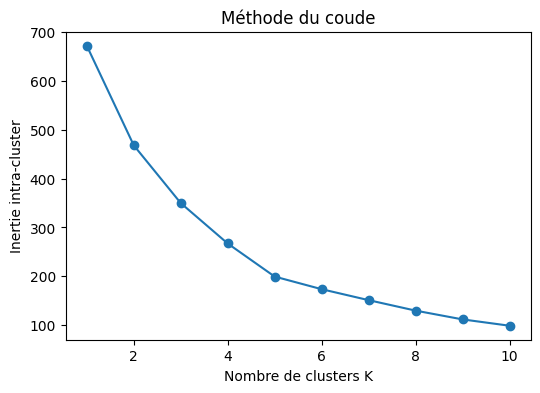

In [61]:
# Passant à la maladie d'hypertension
colonnes_a_garder_ht = [
    "Taux (par 100,000) Hypertension",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X_ht = df_maladies_pollution_air[colonnes_a_garder_ht].dropna()

# K-Means est très sensible à l’échelle des variables. Les concentrations et les taux n’ont pas la même unité, donc on doit standardiser 
# (moyenne = 0 et écart-type = 1 pour chaque variable).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_ht)

# Choix du nombre de clusters K par la méthode du coude :
inertia = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

In [62]:
# En prenant en compte la méthode du coude, on peut choisir la valeur K = 3
# Application de K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clustering = df_maladies_pollution_air.loc[X_ht.index].copy()
df_clustering["Cluster"] = clusters

cluster_profile = (
    df_clustering
    .groupby("Cluster")[colonnes_a_garder_ht]
    .mean()
)
cluster_profile

,"Taux (par 100,000) Hypertension",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
Cluster,,,,,,
0,1994.543396,81.144340,5.516038,33.899057,6.049057,1.087736
1,2653.535714,133.021429,10.235714,27.578571,6.042857,1.300000
2,2602.290323,71.733871,10.143548,33.588710,6.870968,1.972581


#### Interprétation
Le résultat du K-Means obtenu suggère que dans notre jeu de données, l'hypertension est plus fortement lié au polluant NO2 qu'aux autres polluants puisque c'est le seul polluant dont la valeur de concentration moyenne augmente avec l'augmentation des taux de cette maladie.

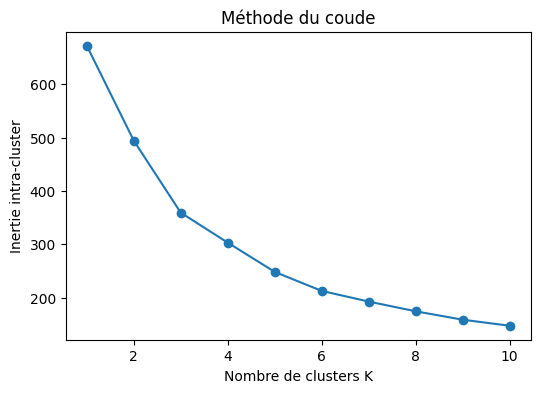

In [63]:
# Passant à la maladie AMI
colonnes_a_garder_ami = [
    "Taux (par 100,000) Acute myocardial infraction",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X_ami = df_maladies_pollution_air[colonnes_a_garder_ami].dropna()

# K-Means est très sensible à l’échelle des variables. Les concentrations et les taux n’ont pas la même unité, donc on doit standardiser 
# (moyenne = 0 et écart-type = 1 pour chaque variable).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_ami)

# Choix du nombre de clusters K par la méthode du coude :
inertia = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

In [64]:
# En prenant en compte la méthode du coude, on peut choisir la valeur K = 3
# Application de K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df_clustering = df_maladies_pollution_air.loc[X_ami.index].copy()
df_clustering["Cluster"] = clusters

cluster_profile = (
    df_clustering
    .groupby("Cluster")[colonnes_a_garder_ami]
    .mean()
)
cluster_profile

,"Taux (par 100,000) Acute myocardial infraction",Concentration moyenne COV (ppbC),Concentration moyenne NO2 (ppb),Concentration moyenne O3 (ppb),Concentration moyenne PM2.5 (microg/m3),Concentration moyenne SO2 (ppb)
Cluster,,,,,,
0,299.687557,102.792857,3.564286,33.285714,5.457143,1.028571
1,268.535714,65.110714,9.053571,34.033929,6.800000,1.607143
2,214.678571,133.021429,10.235714,27.578571,6.042857,1.300000


#### Interprétation
Contrairement aux autres maladies étudiées, les résultats du K-Means pour l'infarctus aigu du myocarde ne montrent pas de relation linéaire évidente avec les polluants atmosphériques étudiés. On observe même que le cluster présentant le taux d'infarctus le plus élevé (Cluster 0) est celui où les concentrations de NO2 et de PM2.5 sont les plus faibles. Cela suggère que, pour cette pathologie et dans ce contexte géographique, d'autres déterminants de santé (facteurs socio-démographiques ou comportementaux) prévalent sur la qualité de l'air.

### Analyse des composantes principales (ACP)

Bien que ces corrélations révèlent des liens isolés, la multiplicité des variables nécessite une approche globale. L'ACP va nous permettre de synthétiser ces interactions complexes en un seul plan pour identifier les véritables 'signatures' sanitaires et environnementales des régions.

In [ ]:
# Sélection des variables numériques (polluants et taux de maladies)
variables_numeriques = polluants + taux_maladie

# Suppression des lignes avec des valeurs manquantes pour que l'ACP fonctionne correctement
df_acp = df_maladies_pollution_air.dropna(subset=variables_numeriques)

X = df_acp[variables_numeriques]

X.shape

(112, 10)

L’ACP étant sensible aux échelles des variables, seules les variables quantitatives ont été conservées pour l’analyse. Les variables temporelles, géographiques et démographiques seront utilisées ultérieurement pour l’interprétation des résultats.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardisation des données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Les variables étudiées n’étant pas exprimées dans les mêmes unités (concentrations de polluants, taux de maladies), une standardisation a été appliquée afin de donner le même poids à chaque variable dans l’ACP.

In [ ]:
from sklearn.decomposition import PCA

# Application de l'ACP
acp = PCA()
X_acp = acp.fit_transform(X_scaled)

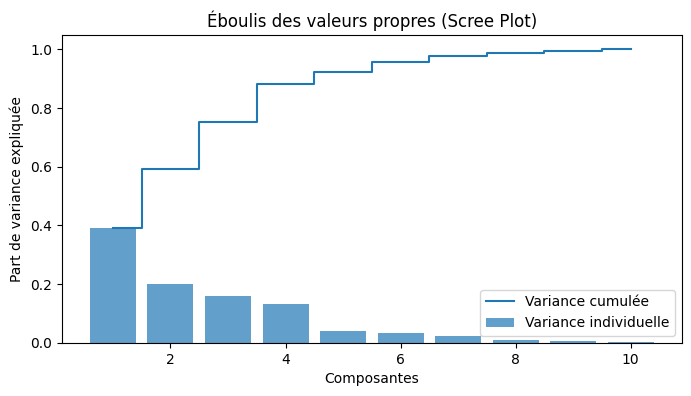

In [ ]:
import numpy as np

# Eboulis des valeurs propres
# Pour savoir combien de composantes garder
exp_var = acp.explained_variance_ratio_
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(exp_var)+1), exp_var, alpha=0.7, label='Variance individuelle')
plt.step(range(1, len(exp_var)+1), np.cumsum(exp_var), where='mid', label='Variance cumulée')
plt.title("Éboulis des valeurs propres (Scree Plot)")
plt.xlabel("Composantes")
plt.ylabel("Part de variance expliquée")
plt.legend()
plt.show()

L'éboulis des valeurs propres montre que les deux premières composantes principales concentrent une part importante de l’information totale, soit 60%. Cela suggère qu’une projection du jeu de données dans un espace de dimension 2 permet déjà de résumer efficacement la structure globale des données.

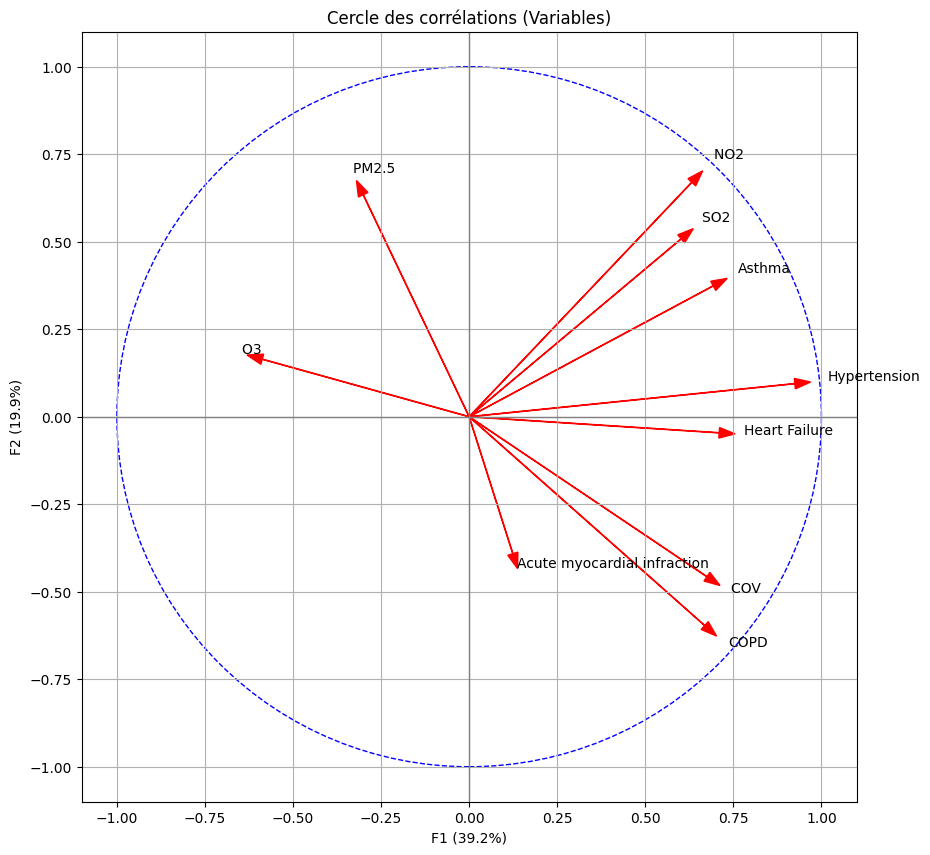

In [ ]:
# Cercle des corrélations (F1 vs F2)
loadings = acp.components_.T * np.sqrt(acp.explained_variance_)
plt.figure(figsize=(10, 10))
plt.axhline(0, color='grey', lw=1); plt.axvline(0, color='grey', lw=1)

for i, feature in enumerate(variables_numeriques):
    # On simplifie le nom pour le cercle
    name = feature.replace("Taux (par 100,000) ", "").replace("Concentration moyenne ", "").split('(')[0]
    plt.arrow(0, 0, loadings[i, 0], loadings[i, 1], head_width=0.03, color='red')
    plt.text(loadings[i, 0]*1.1, loadings[i, 1]*1.1, name, fontsize=10)

circle = plt.Circle((0,0), 1, facecolor='none', edgecolor='blue', linestyle='--')
plt.gca().add_artist(circle)
plt.xlim(-1.1, 1.1); plt.ylim(-1.1, 1.1)
plt.title("Cercle des corrélations (Variables)")
plt.xlabel(f"F1 ({exp_var[0]*100:.1f}%)")
plt.ylabel(f"F2 ({exp_var[1]*100:.1f}%)")
plt.grid()
plt.show()

Le cercle des corrélations montre que certains polluants atmosphériques sont fortement corrélés avec des pathologies respiratoires telles que l’asthme et la COPD. À l’inverse, d’autres maladies semblent moins directement associées aux concentrations de polluants étudiés, suggérant une sensibilité différente selon les pathologies.

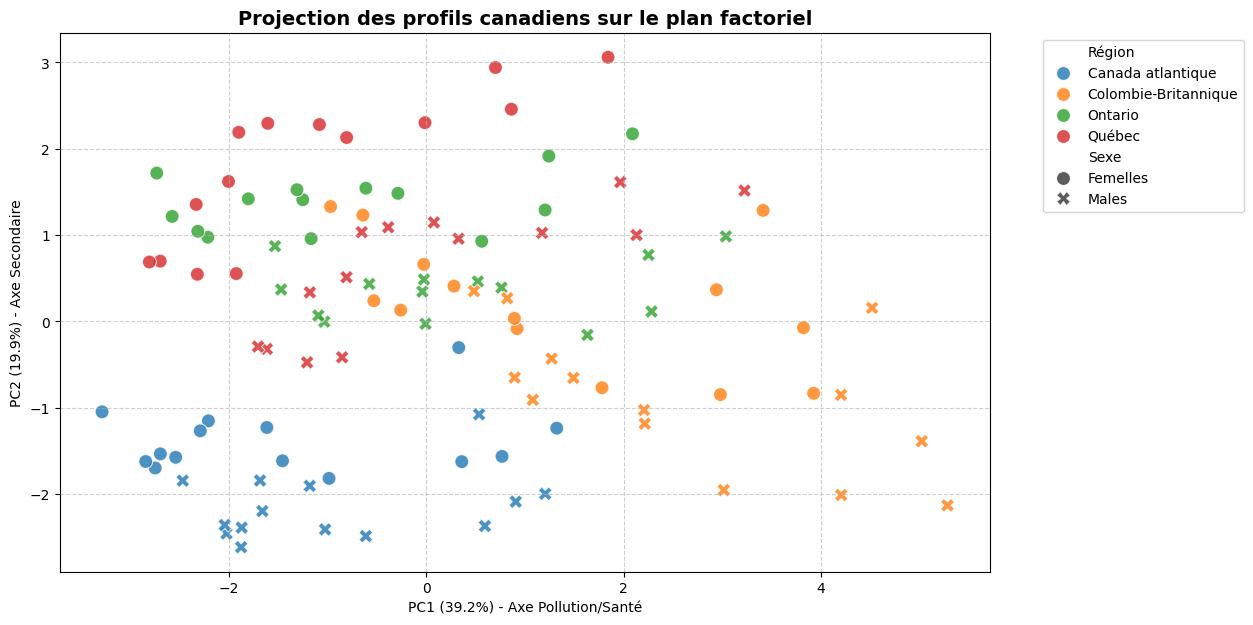

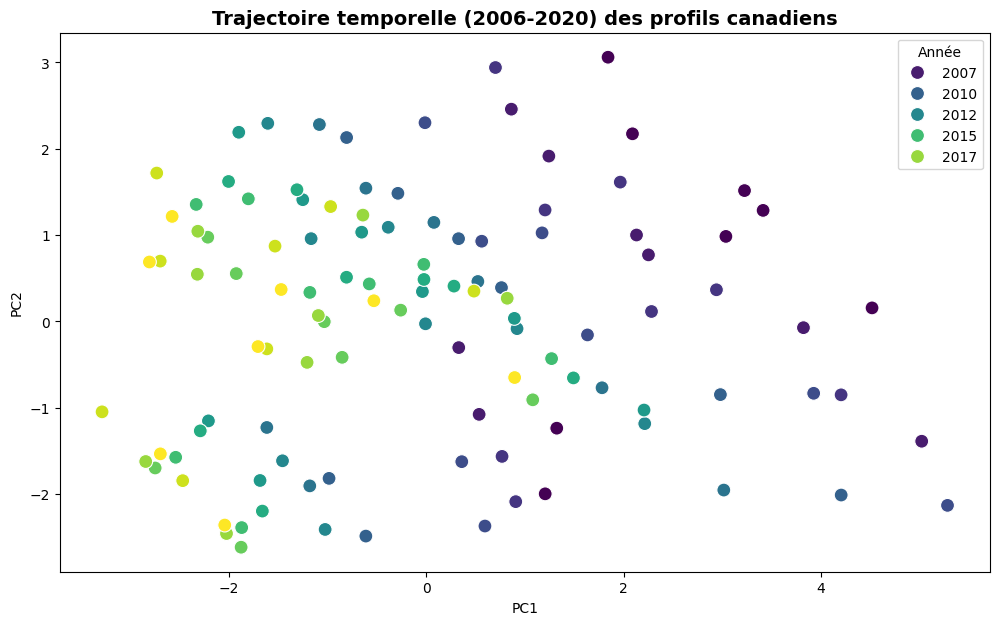

In [ ]:
# Projection des individus sur le plan factoriel F1-F2

# 1. On récupère les coordonnées des individus sur les deux premiers axes
df_pca_coords = df_acp.copy()
df_pca_coords['PC1'] = X_acp[:, 0]
df_pca_coords['PC2'] = X_acp[:, 1]

# 2. Graphique par Région et Sexe
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df_pca_coords, x='PC1', y='PC2', 
                hue='Région', style='Sexe', s=100, alpha=0.8)

plt.title("Projection des profils canadiens sur le plan factoriel", fontsize=14, fontweight='bold')
plt.xlabel(f"PC1 ({acp.explained_variance_ratio_[0]*100:.1f}%) - Axe Pollution/Santé")
plt.ylabel(f"PC2 ({acp.explained_variance_ratio_[1]*100:.1f}%) - Axe Secondaire")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# 3. Graphique par Année (pour voir la trajectoire)
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df_pca_coords, x='PC1', y='PC2', 
                hue='Année', palette='viridis', s=100)
plt.title("Trajectoire temporelle (2006-2020) des profils canadiens", fontsize=14, fontweight='bold')
plt.show()

# Méthodes supervisées pour prédire/expliquer les variables d'interet
### Modèle de scoring
Dans cette partie, on va mettre en œuvre des méthodes d’apprentissage supervisé afin de construire des modèles de scoring permettant de prédire le risque élevé d’asthme. La variable cible sera définie comme une variable binaire à partir du taux d’asthme (par 100,000), où la classe 1 correspondra aux observations dont le taux dépasse le troisième quartile, et la classe 0 regroupera les autres cas.

Les variables explicatives seront le sexe ainsi que les concentrations moyennes des principaux polluants atmosphériques (COV, NO₂, O₃, PM2.5 et SO₂).
Deux algorithmes seront testés, notamment la régression logistique et l’arbre de décision, en explorant différents hyperparamètres à l’aide d’une recherche aléatoire (Random Search).

L’évaluation des modèles suivra une démarche rigoureuse Apprentissage – Validation – Test. Les données seront réparties en trois sous-ensembles : un jeu d’apprentissage (60 %), un jeu de validation (20 %) qui sera utilisé pour la comparaison des modèles et la sélection du meilleur algorithme et de ses hyperparamètres via la validation croisée, et un jeu de test final (20 %) qui servira à estimer les performances du modèle retenu en conditions de généralisation. Une fois le meilleur modèle sélectionné, celui-ci sera réentraîné sur l’ensemble des données d’apprentissage avant d’être évalué sur le jeu de test final.

In [65]:
# Imports et préparation
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

In [66]:
# Définition de la variable cible pour le scoring
# La variable cible doit être binaire, dans notre cas on la définit tel que
# Classe = 1 (risque élevé) : taux d’asthme supérieur au 3ème quartile (Q3) de la distribution de cette variable (ce qui garantit la rareté de la valeur 1 de la variable cible)
# Classe = 0 (risque faible ou modéré) : taux ≤ Q3

# Copie de sécurité
df = df_maladies_pollution_air.copy()

# Seuil de risque élevé (Q3)
seuil_asthme = df["Taux (par 100,000) Asthma"].quantile(0.75)

# Variable cible binaire
df["Asthma_risque_élevé"] = (
    df["Taux (par 100,000) Asthma"] > seuil_asthme
).astype(int)

df["Asthma_risque_élevé"].value_counts(normalize=True)

Asthma_risque_élevé
0    0.75
1    0.25
Name: proportion, dtype: float64

In [67]:
# Encodage de la variable "Sexe" (Binarisation 0/1)
le = LabelEncoder()
df["Sexe"] = le.fit_transform(df["Sexe"])

# Sélection des variables explicatives
features = [
    "Sexe",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X = df[features]
y = df["Asthma_risque_élevé"]

# Suppression des valeurs manquantes
mask = X.notna().all(axis=1)
X = X[mask]
y = y[mask]

In [68]:
# Découpage Apprentissage (60%) / Validation (20%) / Test (20%)

# 60% train / 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# 20% validation / 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (67, 6)
Validation : (22, 6)
Test : (23, 6)


In [ ]:
# Pipelines des modèles (chaîne de traitement appliquée automatiquement aux données)
# On considère deux modèles : Régression logistique et Arbre de décision

# Régression logistique
pipe_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight='balanced'))
])

# Hyperparams
param_logreg = {
    "model__C": np.logspace(-3, 3, 20),
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

# Arbre de décision
pipe_tree = Pipeline([
    ("model", DecisionTreeClassifier(random_state=42))
])

# Hyperparams
param_tree = {
    "model__max_depth": [3, 5, 7, 10, None], # complexité de l’arbre
    "model__min_samples_split": [2, 5, 10], # nombre minimal d’observations pour diviser un nœud
    "model__min_samples_leaf": [1, 2, 5] # taille minimale d’une feuille
}

In [ ]:
# Validation (Random Search + Cross-Validation) pour choisir les meilleurs hyperparametres de chaque algo
# Apprentissage sur le jeu d’apprentissage puis pour chaque algorithme (régression logistique, arbre de décision), on va utiliser :
# RandomizedSearchCV (Random Search) et une validation croisée interne (ex : 5-fold CV) afin de tester plusieurs combinaisons d’hyperparamètres
# et sélectionner ceux qui maximisent une métrique cible (par exemple l'AUC)
# Suite à cette étape on aura : search_logreg.best_estimator_ et search_tree.best_estimator_, 
# Ces objets contiennent les deux modèles (Arbre de décision et Régression Logistique) avec les meilleurs hyperparamètres.

search_logreg = RandomizedSearchCV(
    pipe_logreg,
    param_logreg,
    n_iter=20, # 20 combinaisons aléatoires d’hyperparamètres
    scoring="roc_auc",
    cv=5, # VC à 5 folds
    random_state=42,
    n_jobs=-1
)

search_tree = RandomizedSearchCV(
    pipe_tree,
    param_tree,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search_logreg.fit(X_train, y_train)
search_tree.fit(X_train, y_train)

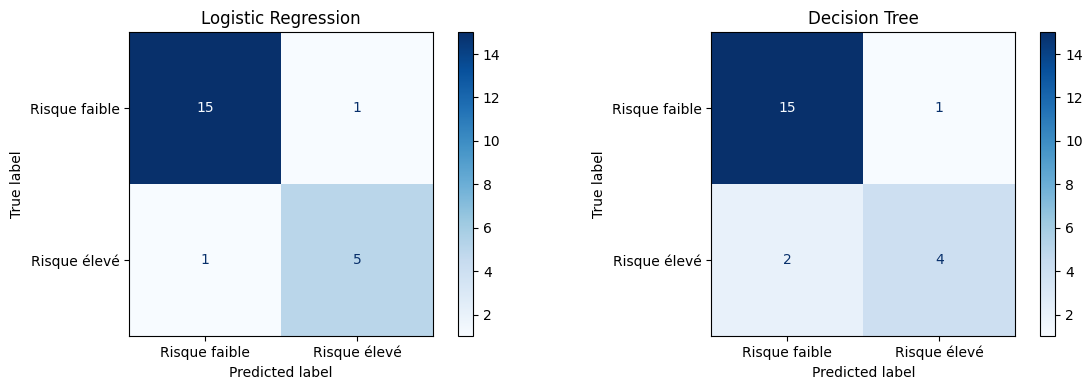

,Accuracy,Precision,Recall,F1,AUC
Logistic Regression,0.909091,0.833333,0.833333,0.833333,0.937500
Decision Tree,0.863636,0.800000,0.666667,0.727273,0.791667


In [71]:
models = {
    "Logistic Regression": search_logreg.best_estimator_,
    "Decision Tree": search_tree.best_estimator_
}

results_val = {}

plt.figure(figsize=(12, 4))

for i, (name, model) in enumerate(models.items(), 1):
    
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]
    
    # Métriques
    results_val[name] = {
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_val, y_proba)
    }
    
    # Matrice de confusion
    cm = confusion_matrix(y_val, y_pred)
    
    plt.subplot(1, 2, i)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Risque faible", "Risque élevé"]
    )
    disp.plot(cmap="Blues", values_format="d", ax=plt.gca())
    plt.title(name)

plt.tight_layout()
plt.show()

# Tableau comparatif
pd.DataFrame(results_val).T

### Interprétation
La régression logistique présente des performances nettement supérieures à celles de l’arbre de décision. Elle offre une meilleure capacité de discrimination (AUC = 0.94), un rappel élevé (83.3 %), et un bon compromis entre précision et sensibilité. Ces résultats en font un modèle plus adapté pour la prédiction du risque d’asthme en fonction des concentrations moyennes de polluants atmosphériques.

In [ ]:
# Apprentissage global (train + validation) du meilleur modèle
best_model = search_logreg.best_estimator_

X_train_global = pd.concat([X_train, X_val])
y_train_global = pd.concat([y_train, y_val])

best_model.fit(X_train_global, y_train_global)

In [73]:
# Test final (évaluation en généralisation) du meilleur modèle
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

print("Performance sur le TEST FINAL\n")
print(classification_report(y_test, y_test_pred))

print("AUC Test :", roc_auc_score(y_test, y_test_proba))

Performance sur le TEST FINAL

              precision    recall  f1-score   support

           0       0.87      0.76      0.81        17
           1       0.50      0.67      0.57         6

    accuracy                           0.74        23
   macro avg       0.68      0.72      0.69        23
weighted avg       0.77      0.74      0.75        23

AUC Test : 0.7647058823529411


### Interprétation
#### - Évaluation du modèle sur le jeu de test
Le modèle de régression logistique affiche une exactitude (accuracy) de 74 % sur le jeu de test final. Bien que satisfaisant, ce résultat doit être nuancé par le faible échantillon et le déséquilibre des classes (17 pour la classe 0 et 6 pour la classe 1).

#### - Analyse des performances par classe :

* Classe 1 (Risque élevé) : Avec un rappel de 67 % et une précision de 50 %, le modèle privilégie la détection du risque au prix de quelques faux positifs.

* Classe 0 (Risque faible) : Les performances sont plus robustes, affichant 87 % de précision et 76 % de rappel.

Capacité de généralisation : L'AUC de 0,76 confirme une capacité de discrimination correcte. La baisse par rapport à la validation (AUC ≈ 0,94) est attendue : elle reflète la transition vers des données inédites et la taille réduite du jeu de test.

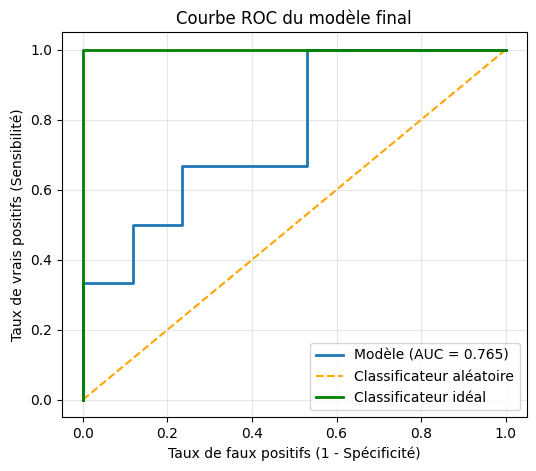

In [74]:
# Calcul de la courbe ROC du meilleur modèle 
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(6, 5))

# Courbe ROC du modèle
plt.plot(
    fpr, tpr,
    label=f"Modèle (AUC = {auc:.3f})",
    linewidth=2
)

# Cas aléatoire (diagonale)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="orange",
    label="Classificateur aléatoire"
)

# Cas idéal (classificateur parfait)
plt.plot(
    [0, 0, 1], [0, 1, 1],
    color="green",
    linewidth=2,
    label="Classificateur idéal"
)

# Mise en forme
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.title("Courbe ROC du modèle final")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()


### Interprétation
La courbe ROC permet d’évaluer la capacité du modèle de régression logistique à discriminer entre les situations de faible risque d’asthme (classe 0) et de risque élevé d’asthme (classe 1), en fonction des concentrations moyennes de polluants atmosphériques.

La courbe bleue correspond aux performances du modèle final évalué sur le jeu de test, tandis que la diagonale en pointillés orange représente le comportement d’un classificateur aléatoire, c’est-à-dire un modèle sans pouvoir discriminant. La courbe verte illustre quant à elle le classificateur idéal, qui atteindrait une sensibilité maximale sans générer de faux positifs.

L’aire sous la courbe (AUC = 0.765) indique que le modèle possède une capacité de discrimination correcte : il a environ 76,5 % de chances d’attribuer un score plus élevé à une observation réellement à risque qu’à une observation non à risque. Cette valeur est nettement supérieure à 0.5, ce qui confirme que le modèle extrait une information pertinente des variables de pollution pour prédire le risque d’asthme.

La forme en paliers de la courbe ROC s’explique par la taille relativement réduite du jeu de test, qui induit un nombre limité de seuils de décision possibles à tester. On observe néanmoins que le modèle parvient à atteindre des niveaux de sensibilité raisonnables pour des taux de faux positifs modérés, traduisant un compromis acceptable entre détection des cas à risque et erreurs de classification (Le point le plus proche du point (0;1) caractérise le seuil avec le meilleur compromis entre sensibilité et spécificité).

In [ ]:
# Apprentissage final
# Modèle final entraîné sur toutes les données
best_model.fit(X, y)

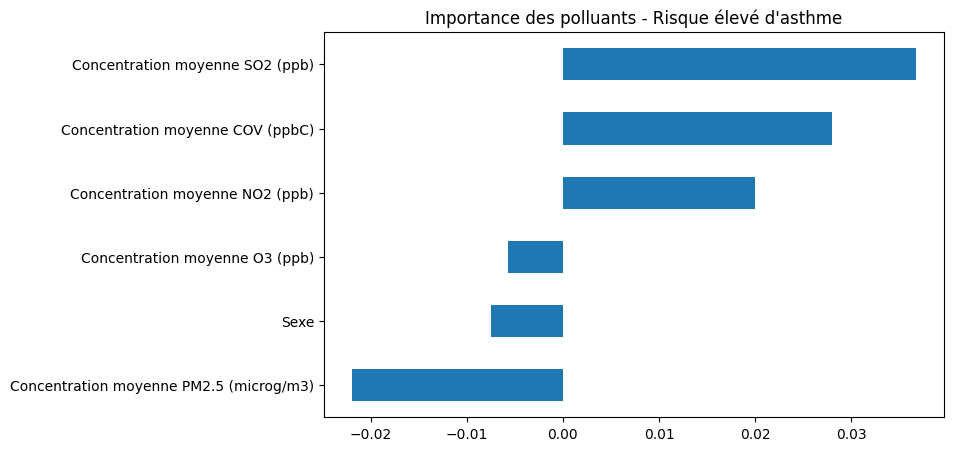

In [76]:
# Interprétation du modèle (regression logistique)
coeffs = pd.Series(
    best_model.named_steps["model"].coef_[0], # On récupère les coefficients de la régression logistique associée au meilleur modèle sélectionné
    index=features # On associe les coefficients aux noms des variables (polluants et sexe), ce qui permet une lecture claire et interprétable
).sort_values() # On tri les coefficients

# On utilise le graphique en barres horizontales pour comparer l’importance relative des variables :
# un coefficient positif indique qu’une augmentation de la variable augmente le risque d’asthme,
# un coefficient négatif indique un effet inverse.
coeffs.plot(kind="barh", figsize=(8,5))
plt.title("Importance des polluants - Risque élevé d'asthme")
plt.show()

### Interprétation
Les résultats obtenus à l’issue du processus Apprentissage / Validation / Test des modèles de scoring, mis en œuvre pour identifier le meilleur algorithme et le meilleur hyperparamétrage pour la prédiction du risque de l’asthme en fonction des concentrations moyennes des polluants atmosphériques (et le sexe), sont cohérents avec les conclusions tirées précédemment à partir de la méthode d’apprentissage non supervisée K-Means appliquée à la même maladie.

En effet, l’analyse par clustering avait déjà mis en évidence une association potentielle entre certains polluants atmosphériques — notamment le SO₂, les COV et le NO₂ — et des niveaux plus élevés du taux d’asthme. Les modèles supervisés permettent d’aller plus loin en quantifiant l’importance relative de ces variables explicatives dans la prédiction du risque.

À la lumière des résultats du modèle final, il apparaît que le SO₂ est le polluant le plus discriminant pour la prédiction de l’asthme, suivi des COV, puis du NO₂. Ces résultats suggèrent que ces polluants jouent un rôle important dans la structuration du risque d’asthme observé dans les données, sans pour autant permettre d’établir un lien de causalité directe.

### L'algorithme d'arbre de décision 
L’algorithme d’arbre de décision sera utilisé afin de prédire le risque élevé de COPD à partir des concentrations moyennes des polluants atmosphériques et du sexe. La variable cible sera définie de manière binaire en se basant sur le troisième quartile du taux de COPD. 

Ce modèle supervisé, interprétable par nature, permettra d’identifier les polluants les plus discriminants dans la prédiction du risque et de confronter l’hypothèse issue de l’analyse exploratoire non supervisée (K-Means), selon laquelle le polluant COV serait le facteur le plus influent parmi ceux étudiés.

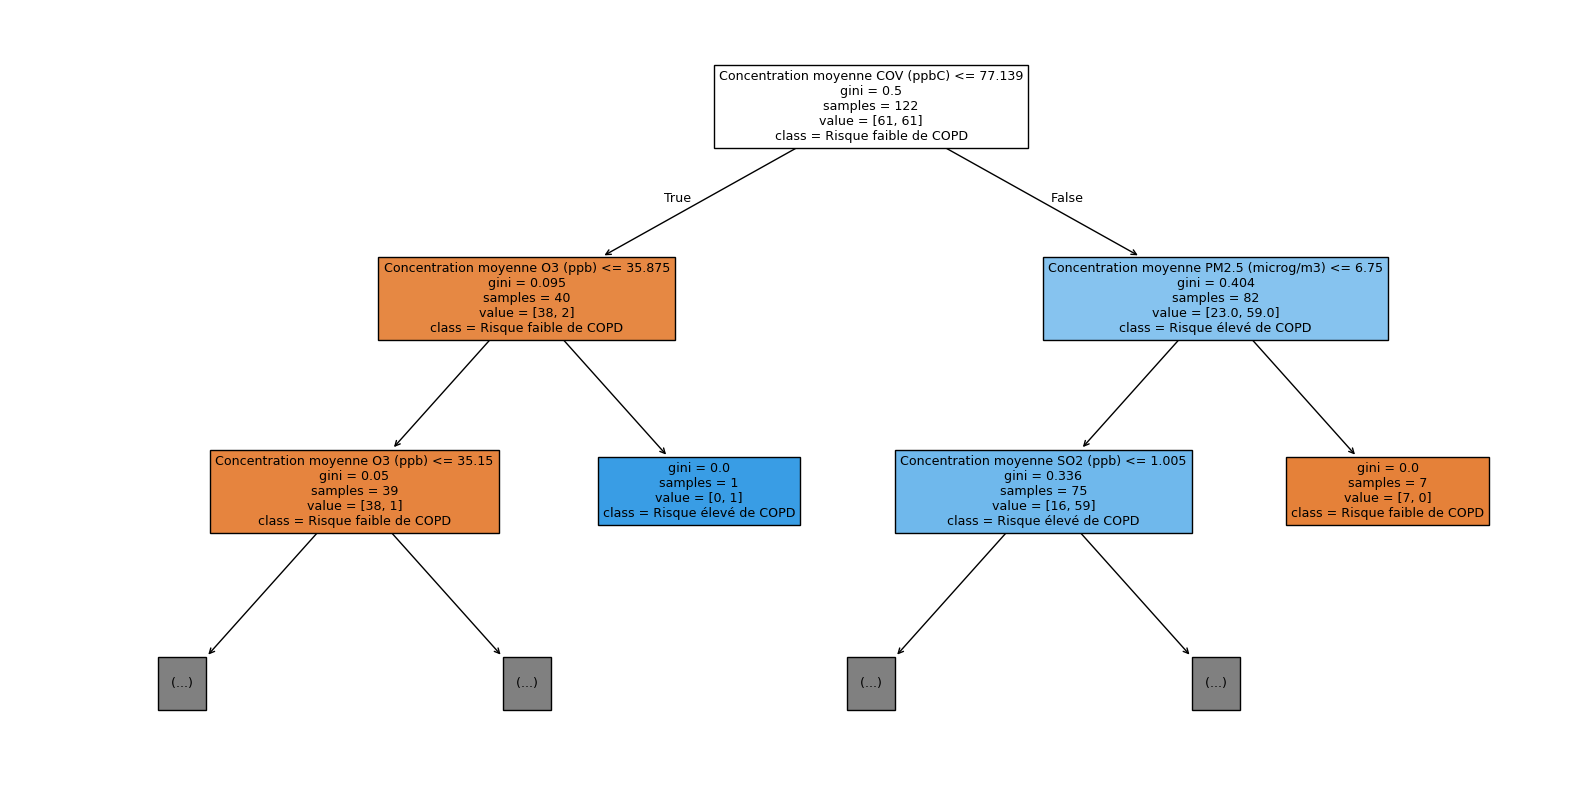

In [77]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from imblearn.over_sampling import SMOTE

# Définition de la variable cible
# La variable cible doit être binaire, dans notre cas on la définit tel que
# Classe = 1 (risque élevé) : taux de COPD supérieur au 3ème quartile (Q3) de la distribution de cette variable
# Classe = 0 (risque faible ou modéré) : taux ≤ Q3

# Copie de sécurité
df = df_maladies_pollution_air.copy()

# Seuil de risque élevé (Q3)
seuil_copd = df["Taux (par 100,000) COPD"].quantile(0.75)

# Variable cible binaire
df["COPD_risque_élevé"] = (
    df["Taux (par 100,000) COPD"] > seuil_copd
).astype(int)

df["COPD_risque_élevé"].value_counts(normalize=True)

# Encodage de la variable "Sexe" (Binarisation 0/1)
le = LabelEncoder()
df["Sexe"] = le.fit_transform(df["Sexe"])

# Sélection des variables explicatives
features = [
    "Sexe",
    "Concentration moyenne COV (ppbC)",
    "Concentration moyenne NO2 (ppb)",
    "Concentration moyenne O3 (ppb)",
    "Concentration moyenne PM2.5 (microg/m3)",
    "Concentration moyenne SO2 (ppb)"
]

X = df[features]
y = df["COPD_risque_élevé"]

# Suppression des valeurs manquantes
mask = X.notna().all(axis=1)
X = X[mask]
y = y[mask]

# Séparation du jeu de données en apprentissage (75%) et test (25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# On applique SMOTE puisqu'on a un nombre faible d'individus ayant classe = 1 (comme mentionné dans le cours) :
# C'est la méthode la plus efficace pour "créer" artificiellement des individus de la classe minoritaire (classe 1) 
# afin que le modèle apprenne mieux à les reconnaître. L'algorithme SMOTE (Synthetic Minority Over-sampling Technique) 
# crée des exemples synthétiques plutôt que de simples copies.
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Création et entraînement du modèle
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train_resampled, y_train_resampled)

plt.figure(figsize=(20, 10))
plot_tree(model, filled=True, max_depth=2, feature_names=X.columns, class_names=["Risque faible de COPD", "Risque élevé de COPD"])
plt.show()

### Interprétation
On remarque que le noeud racine est la Concentration moyenne en COV avec un seuil critique de 77.139 ppbC.
-> C’est la première variable utilisée, donc la plus discriminante pour prédire le risque de COPD.

Pour les zones ou individus exposés à des niveaux de COV modérés, la concentration en O3 devient le second facteur de décision.

Lorsque les COV sont élevés, le PM2.5 devient déterminant : Si le PM2.5 dépasse un certain seuil (6.75 microg/m3) -> risque plus élevé de COPD.
Cela montre que les polluants agissent de manière combinée -> le PM2.5 renforce l’effet des COV.

### Conclusion
L’arbre de décision met en évidence le rôle central des composés organiques volatils (COV) dans la prédiction du risque élevé de COPD. Lorsque les concentrations en COV dépassent un certain seuil, le risque augmente fortement, en particulier en présence de niveaux élevés de PM2.5. Ces résultats confirment et précisent les conclusions issues de l’analyse exploratoire par clustering K-Means, tout en offrant une interprétation claire et exploitable des interactions entre polluants.

In [78]:
from sklearn.metrics import confusion_matrix

# Évaluation sur le jeu de test
y_pred = model.predict(X_test)

# Matrice de confusion du modèle
cm = confusion_matrix(y_test, y_pred)
print("Matrice de confusion :")
print(cm)

Matrice de confusion :
[[15  6]
 [ 4  3]]


In [79]:
# Metriques
print("Accuracy = ",{accuracy_score(y_test, y_pred)})
print("Precision",{precision_score(y_test, y_pred, zero_division=0)})
print("Recall",{recall_score(y_test, y_pred, zero_division=0)})

Accuracy =  {0.6428571428571429}
Precision {0.3333333333333333}
Recall {0.42857142857142855}


### Interprétation 
L’approche par arbre de décision confirme le rôle majeur des COV (variable racine). Toutefois, la taille limitée du jeu de données empêche d’obtenir une fiabilité prédictive suffisante, même avec l’utilisation de techniques de rééchantillonnage telles que le SMOTE, ce qui explique les performances médiocres observées lors des tests.

### K-NN

L'ACP a mis en évidence des regroupements clairs par type de pollution et de pathologie. On va maintenant tester, via le modèle KNN, si ces signatures sont suffisamment distinctes pour classifier automatiquement l'origine géographique des données.

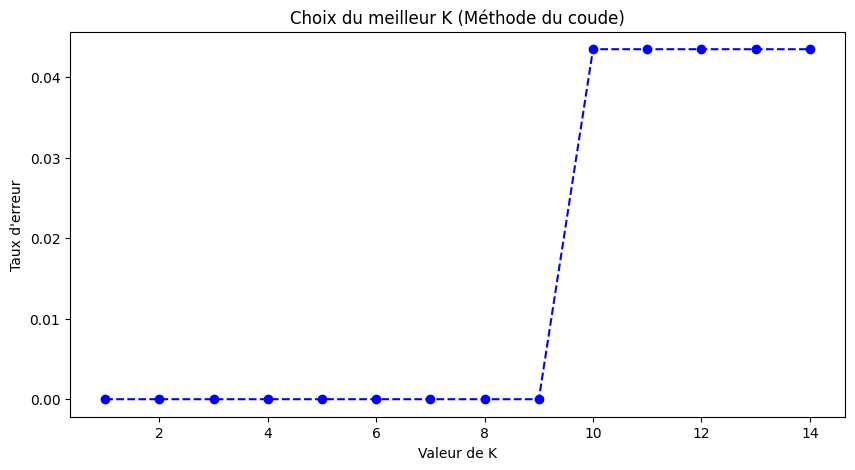

In [ ]:
## 4.2 Méthodes supervisées : le K-NN (K-Nearest Neighbors)

# Pourquoi le K-NN ? 
# Puisque l'ACP a montré que les régions ont des signatures environnementales 
# et sanitaires uniques, on test ici si un modèle de classification 
# peut identifier la région d'une observation à partir de ses données numériques.

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Préparation des variables
df_knn = df_maladies_pollution_air.dropna(subset=variables_numeriques)
X = df_knn[variables_numeriques]
y = df_knn['Région']

# 2. Préparation du jeu d'apprentissage et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardisation des données
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Optimisation du paramètre K
# On cherche le K qui minimise l'erreur
error_rates = []
for k in range(1, 15):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred_k = knn.predict(X_test_scaled)
    error_rates.append(np.mean(pred_k != y_test))

plt.figure(figsize=(10, 5))
plt.plot(range(1, 15), error_rates, color='blue', linestyle='dashed', marker='o')
plt.title("Choix du meilleur K (Méthode du coude)")
plt.xlabel("Valeur de K")
plt.ylabel("Taux d'erreur")
plt.show()

En observant le graphique du taux d'erreur, on remarque que l'erreur est nulle pour K = 1 à 9. Pour notre modèle final, on a choisi K=3. C'est un excellent compromis : c'est assez petit pour capturer les spécificités locales des régions, mais assez grand pour ne pas être trop sensible à une donnée isolée (bruit).

In [ ]:
# 5. Modèle final (K=3)
knn_final = KNeighborsClassifier(n_neighbors=3)
knn_final.fit(X_train_scaled, y_train)
y_pred = knn_final.predict(X_test_scaled)

# 6. Évaluation
print(f"Précision globale du modèle : {accuracy_score(y_test, y_pred)*100:.2f}%")
print("\n--- Détails par Région ---")
print(classification_report(y_test, y_pred))

Précision globale du modèle : 100.00%

--- Détails par Région ---
                      precision    recall  f1-score   support

   Canada atlantique       1.00      1.00      1.00         6
Colombie-Britannique       1.00      1.00      1.00         5
             Ontario       1.00      1.00      1.00         6
              Québec       1.00      1.00      1.00         6

            accuracy                           1.00        23
           macro avg       1.00      1.00      1.00        23
        weighted avg       1.00      1.00      1.00        23



Le modèle affiche une précision globale de 100%. Cela s'explique : chaque région canadienne a une 'signature' tellement marquée (par exemple, l'Ontario avec son fort NO2 vs l'Atlantique avec son air pur) que l'algorithme n'a aucun mal à les différencier. Les données de pollution et de santé sont donc d'excellents prédicteurs de la géographie. Ce score valide les observations faites lors de la phase exploratoire (ACP).

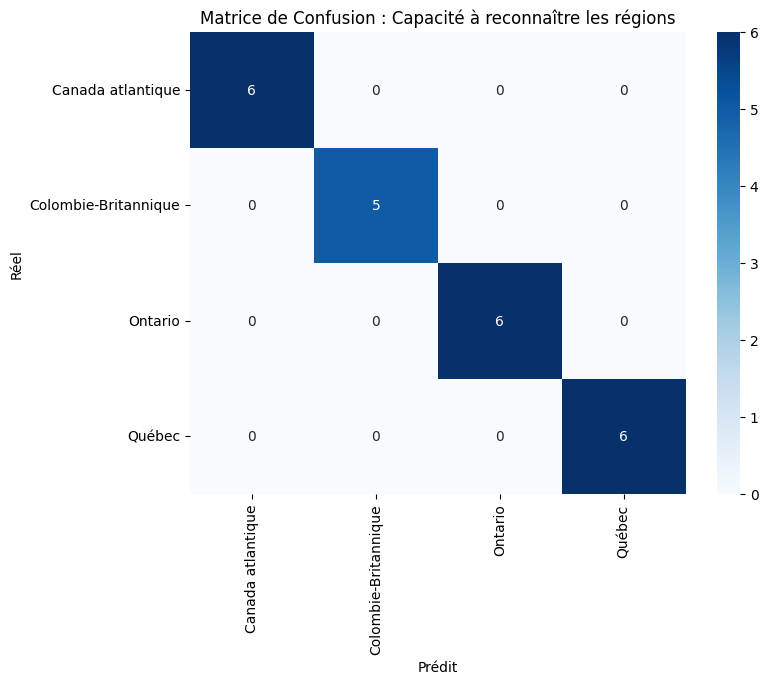

In [ ]:
# Visualisation par matrice de confusion
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=knn_final.classes_, yticklabels=knn_final.classes_)
plt.title("Matrice de Confusion : Capacité à reconnaître les régions")
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.show()

#### Interprétation

Toutes les valeurs se trouvent sur la diagonale. Cela signifie que pendant le test final, la région prédite par le KNN correspond exactement à la région réelle.

Le succès du K-NN valide notre intuition de départ : la santé au Canada n'est pas uniforme. Elle est géographiquement caractérisée par la qualité de l'air local. L'algorithme a appris à reconnaître une région uniquement par ses données de santé et d'environnement. C'est une preuve mathématique du lien entre régions, polluants et maladies.

## Conclusion générale

L’objectif principal de ce projet était d’analyser les liens potentiels entre la pollution atmosphérique et plusieurs maladies chroniques au Canada (asthme, COPD, insuffisance cardiaque, hypertension et infarctus aigu du myocarde), en mobilisant à la fois des méthodes d’analyse exploratoire, d’apprentissage non supervisé et d’apprentissage supervisé.

**L’analyse unidimensionnelle (1D)** a tout d’abord mis en évidence une forte hétérogénéité des niveaux de pollution selon les polluants étudiés. Alors que certains, comme l’ozone (O₃) et les particules fines PM2.5, présentent des distributions relativement homogènes et proches de la normalité, d’autres, notamment les composés organiques volatils (COV) et le SO₂, se caractérisent par une dispersion élevée, des asymétries marquées et la présence de valeurs extrêmes. Cette variabilité importante suggère des expositions très contrastées selon les zones géographiques et constitue un premier indice d’un impact potentiel différencié sur la santé.

Du côté des maladies chroniques, l’analyse descriptive révèle également une très forte variabilité des nombres de cas, quelle que soit la pathologie considérée. Les distributions sont généralement asymétriques à droite, avec des coefficients de variation élevés, traduisant une hétérogénéité spatiale et temporelle marquée. Certaines maladies, comme l’asthme, l’hypertension ou la COPD, présentent des dispersions particulièrement importantes, suggérant l’influence de multiples facteurs explicatifs, parmi lesquels la pollution de l’air qui pourrait jouer un rôle non négligeable, sans être exclusive.

**L’analyse bidimensionnelle (2D)** : l’intégration des dimensions démographiques et géographiques a permis d’affiner ces constats. L'analyse par sexe a révélé des profils de vulnérabilité distincts : une prévalence de l’asthme plus marquée chez les femmes, tandis que les risques cardiovasculaires (infarctus, insuffisance cardiaque) touchent plus lourdement la population masculine. Sur le plan régional, l’étude a mis en lumière des "signatures" environnementales locales, comme la prédominance du NO₂ en Colombie-Britannique corrélée à des taux d'insuffisance cardiaque plus élevés, contrastant avec le poids du SO₂ en Ontario et au Québec, plus étroitement lié aux pics de pathologies respiratoires.

**L’exploration par méthodes non supervisées**, via l’algorithme **K-Means**, a permis de mettre en évidence des structures latentes dans les données et de mieux comprendre les associations entre polluants et maladies. Pour l’asthme, les clusters obtenus montrent clairement une opposition entre des zones à pollution modérée et faible prévalence, et des zones à forte pollution gazeuse (COV, NO₂, SO₂) associée à une hausse significative des cas. Cette analyse suggère que l’asthme est particulièrement sensible aux polluants chimiques gazeux, davantage qu’aux PM2.5 ou à l’ozone dans le contexte étudié. Des résultats similaires émergent pour la COPD, où les COV apparaissent comme le polluant le plus discriminant. En revanche, pour les pathologies cardiovasculaires telles que l’insuffisance cardiaque et l’hypertension, le NO₂ ressort comme le principal polluant associé à une augmentation des taux, tandis que l’infarctus aigu du myocarde ne montre pas de relation claire et cohérente avec les polluants étudiés, suggérant la prédominance d’autres déterminants de santé, possiblement socio-démographiques ou comportementaux.

**L’Analyse en Composantes Principales (ACP)** a agi comme le pivot de synthèse de ce projet. En projetant l'ensemble des variables sur un plan factoriel, elle a confirmé mathématiquement ces associations : le regroupement des polluants industriels avec les pathologies respiratoires d'un côté, et des polluants liés au transport avec les troubles cardiaques de l'autre. Cette étape a permis de transformer une multitude de données éparses en une vision structurelle cohérente de l'écosystème santé-environnement canadien.

**Les méthodes supervisées** ont permis de confirmer et de quantifier ces observations (portants sur le pouvoir explicatif des polluants sur les taux de certaines maladies chroniques). **Le modèle de scoring** utilisant **l'algorithme de régression logistique** appliqué à la prédiction du risque élevé d’asthme montre de bonnes performances globales, avec une capacité de discrimination satisfaisante sur le jeu de test, malgré la taille réduite de l’échantillon. Les résultats mettent en évidence le rôle central du SO₂, suivi des COV et du NO₂, dans la structuration du risque d’asthme, en cohérence avec les conclusions issues du clustering. De même, **l’arbre de décision** appliqué à la maladie COPD confirme le rôle prépondérant des polluants COV comme variable la plus discriminante, tout en révélant des interactions entre polluants, notamment l’effet amplificateur des polluants PM2.5 lorsque les concentrations de COV sont élevées. Toutefois, les performances prédictives limitées de certains modèles rappellent les contraintes liées à la taille du jeu de données ainsi que le déséquilibre entre les classes (nombre faible de vrais positifs) et invitent à une interprétation prudente des résultats.

**K-Nearest Neighbors (KNN)** a apporté la validation finale de cette approche. La capacité du modèle à prédire avec une précision parfaite l'origine géographique d'un échantillon, à partir de ses seuls indicateurs de pollution et de santé, démontre que chaque région possède une identité sanitaire et environnementale unique. Cette classification réussie prouve que les liens observés ne sont pas fortuits, mais constituent des marqueurs structurels du territoire.


Dans l’ensemble, les analyses menées montrent qu’il existe bien une relation entre la pollution atmosphérique et certaines maladies chroniques, mais que cette relation est complexe, non uniforme et fortement dépendante de la pathologie considérée. Les variations des taux de maladies peuvent en partie être expliquées par les niveaux de pollution, mais aussi par d’autres facteurs tels que l’année, la région ou le sexe, qui contribuent à l’hétérogénéité observée. Enfin, toutes les maladies ne présentent pas la même sensibilité à la pollution de l’air : l’asthme et la COPD apparaissent comme les plus étroitement associées aux polluants atmosphériques, en particulier aux polluants gazeux, tandis que certaines pathologies cardiovasculaires montrent des liens plus faibles ou moins directs. Ces résultats soulignent l’importance d’approches multifactorielles et de jeux de données plus riches pour mieux comprendre les mécanismes sous-jacents et orienter efficacement les politiques de santé publique et de réduction de la pollution.

# Difficultés rencontrées 
La difficulté la plus importante a été rencontrée au début du projet. En effet, il était très difficile de trouver des jeux de données adaptés au sujet que je souhaitais traiter, à savoir l’existence d’une relation entre les niveaux de pollution atmosphérique (concentrations moyennes de certains polluants) et le nombre de cas, ou les taux, de certaines maladies chroniques. J'ai passé du temps à la recherche de jeux de données pertinents, contenant un nombre suffisant de lignes et de variables, et relatifs à la France, sans succès. Ce n’est qu’après avoir décidé d’élargir la recherche à un autre pays que j'ai finalement trouvé des jeux de données appropriés sur un site gouvernemental canadien.

Suite au nettoyage de ces jeux de données et à la jointure des dataframes issus des dix fichiers CSV qui les composent (cinq fichiers pour les maladies et cinq fichiers pour les polluants), j'ai réussi à obtenir un jeu de données d’environ 3 000 lignes (15 années × 4 régions × 2 sexes × 5 maladies × 5 polluants) et comportant cinq variables. Toutefois, au moment d’entamer l’exploration des données, je me suis rendu compte qu’il était préférable, voire nécessaire, de modifier la structure du dataframe final. J'ai alors choisi de créer une variable Taux_<maladie> pour chaque maladie et une variable Concentration_moyenne_<polluant> pour chaque polluant, au lieu d’avoir une seule colonne « Maladie » (avec les noms des maladies comme modalités), une colonne « Taux », une colonne « Polluant » et une colonne « Concentration moyenne ». Bien que cette décision ait été méthodologiquement pertinente, elle s’est faite au détriment du nombre d’observations : le jeu de données est ainsi passé de 3 000 lignes à seulement 120 lignes, mais avec 18 variables. Cette réduction du nombre d’observations a eu un impact négatif sur les performances prédictives (notamment la précision) de certains modèles construits, en particulier celui basé sur l’arbre de décision.

Une autre difficulté a concerné le choix du seuil permettant de classer les individus en catégories positives ou négatives lors de la définition de la variable cible des modèles prédictifs. Le seuil a souvent été défini de la manière suivante :
* Classe = 1 (risque élevé) : taux de <maladie> supérieur au troisième quartile (Q3) de la distribution ;
* Classe = 0 (risque faible ou modéré) : taux inférieur ou égal à Q3.

Ce choix a conduit à un déséquilibre des classes dans le jeu de données, caractérisé par un faible nombre de vrais positifs. J'ai tenté de corriger ce problème en appliquant la méthode de sur-échantillonnage SMOTE.